# Лабораторная работа 1 — рабочий ноутбук

**ФИО: Бузычков Никита Фёдорович**

**Файлы данных: clients.csv, transactions.csv**

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")

RAW_CLIENTS = "data/S03/clients.csv"
RAW_TXN = "data/S03/transactions.csv"

BASE_START = pd.Timestamp("2024-01-01")   # базовый период 2024 год
EVAL_START = pd.Timestamp("2025-01-01")   # оцениваемый период январь-июнь 2025
DATA_END = pd.Timestamp("2025-07-01")     # первый день после конца данных
SNAPSHOT = pd.Timestamp("2025-06-30")     # дата среза справочника клиентов
H1_2024_END = pd.Timestamp("2024-07-01")  # конец января-июня 2024 для сравнения одинаковых месяцев
BASE_MONTHS, EVAL_MONTHS = 12, 6          # окна разной длины, поэтому всё считаем в расчёте на месяц

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

### 1.1 Загрузка `clients.csv`

Сначала прочитаем файл с настройками по умолчанию.

In [2]:
clients_naive = pd.read_csv(RAW_CLIENTS)
print(clients_naive.shape)
display(clients_naive.head(5))
display(clients_naive.dtypes)

(5713, 16)


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C003559,1982-07-23,М,казань,Зарплатный,Базовый,Дебетовая,16.11.2021,13.05.2025,Зарплата в нашем банке,60400.0,Да,2024-10,NaN,253,Да
1,C000372,1983-01-11,М,Н. Новгород,Массовый,Базовый,Кредитная,12.07.2015,08.12.2017,Не указан,84900.0,Да,2024-12,NaN,106,Да
2,C003416,1967-07-10,М,Н. Новгород,Массовый,Базовый,Дебетовая,09.12.2020,06.12.2024,Зарплата в другом банке,72200.0,Да,2024-08,NaN,424,Да
3,C004637,1986-11-21,Ж,Новосибирск,Зарплатный,Базовый,Кредитная,30.08.2014,23.03.2017,Зарплата в нашем банке,97000.0,Нет,NaN,NaN,406,Да
4,C005995,1987-10-27,М,г. Новосибирск,Массовый,Серебро,Дебетовая,22.07.2016,10.07.2017,Не указан,NaN,Да,2025-06,NaN,531,Да


client_id                 str
birth_date                str
gender                    str
city                      str
segment                   str
loyalty_tier              str
card_type                 str
registration_date         str
card_open_date            str
income_source             str
monthly_income        float64
has_mobile_app            str
app_last_login            str
satisfaction_score    float64
branch_code             int64
marketing_opt_in          str
dtype: object

Сравним с тем как значения записаны в самом файле.

In [3]:
with open(RAW_CLIENTS, encoding="utf-8") as f:
    print(repr(f.readline()))
    print(repr(f.readline()))

'client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in\n'
'C003559,1982-07-23,М,казань,Зарплатный,Базовый,Дебетовая,16.11.2021,13.05.2025,Зарплата в нашем банке,60400.0,Да,2024-10,,00253,Да\n'


Что можно увидеть:

- Кириллица отобразилась корректно с кодировкой по умолчанию, значит это utf-8
- Разделителем является запятая
- Десятичным знаком является точка
- Тип satisfaction_score прочитан как float64, потому что в нём есть пропуски. Но по смыслу это целая шкала от 1 до 5, поэтому возьмём Int64
- branch_code в файле записан как 00253, а в таблице отображен как 253 с типом int64, из-за чего теряются ведущие нули. Поэтому прочитаем как строку
- Даты остались текстом и записаны по разному

Пока категориальные поля прочитаем как строки, их значения нужно будет проверить далее. Пропуском считаем только пустую ячейку, чтобы pandas не превращал в NaN значения вроде `NA` или `None`.

In [4]:
CLIENTS_DTYPES = {
    "client_id": "string",
    "birth_date": "string",
    "gender": "string",
    "city": "string",
    "segment": "string",
    "loyalty_tier": "string",
    "card_type": "string",
    "registration_date": "string",
    "card_open_date": "string",
    "income_source": "string",
    "monthly_income": "float64",
    "has_mobile_app": "string",
    "app_last_login": "string",
    "satisfaction_score": "Int64",
    "branch_code": "string",
    "marketing_opt_in": "string",
}

clients_df = pd.read_csv(
    RAW_CLIENTS,
    sep=",",
    encoding="utf-8",
    dtype=CLIENTS_DTYPES,
    keep_default_na=False,
    na_values=[""],
)

assert list(clients_df.columns) == list(CLIENTS_DTYPES)

# сводка по колонкам
def overview(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_unique": df.nunique(),
        "n_missing": df.isna().sum(),
        "missing_%": (df.isna().mean() * 100).round(2),
        "example": df.iloc[5],
    })

print(clients_df.shape)
display(overview(clients_df))

(5713, 16)


,dtype,n_unique,n_missing,missing_%,example
client_id,string,5658,0,0.00,C002443
birth_date,string,4831,0,0.00,1986-03-03
gender,string,2,0,0.00,Ж
city,string,17,0,0.00,Новосибирск
segment,string,4,0,0.00,Массовый
loyalty_tier,string,4,0,0.00,Базовый
card_type,string,3,0,0.00,Кредитная
registration_date,string,3240,0,0.00,04.09.2019
card_open_date,string,2678,0,0.00,19.10.2019
income_source,string,3,0,0.00,Не указан


### 1.2 Загрузка `transactions.csv`

Как и для справочника, сначала посмотрим, как записаны первые строки файла. Кодировку пока не знаем, поэтому читаем с `errors="replace"`: символы, которые не укладываются в utf-8, Python заменит на "�"

In [5]:
with open(RAW_TXN, encoding="utf-8", errors="replace") as f:
    print(repr(f.readline()))
    print(repr(f.readline()))

'txn_id;client_id;txn_datetime;amount;currency;category;mcc_code;channel;status\n'
'990048;C002733;2023-12-11 14:53:57;886,99;RUB;����� � ��������;4814;���;�������\n'


Латиница и цифры читаются, а на месте кириллицы "�", значит файл не в utf-8. Для выгрузки на русском языке можно использовать cp1251. Проверим на первых 5 строках.

In [6]:
step = pd.read_csv(RAW_TXN, encoding="cp1251", nrows=5)
print(step.shape)
display(step)

(5, 1)


,txn_id;client_id;txn_datetime;amount;currency;category;mcc_code;channel;status
990048;C002733;2023-12-11 14:53:57;886,99;RUB;Связь и Интернет;4814;СБП;успешно
990003;C005931;2023-12-11 15:54:40;2146,59;RUB;Кафе и рестораны;5812;СБП;успешно
100001;C004354;2024-01-01 00:41:20;1674,47;RUB;Онлайн-сервисы;5815;Карта;успешно
100002;C004175;2024-01-01 02:22:46;1656,22;RUB;АЗС;5541;Токен;успешно
100003;C004899;2024-01-01 02:38:33;3039,64;RUB;Развлечения и досуг;7832;СБП;успешно


Ошибки кодировки нет и кириллица читается, значит кодировка cp1251 подошла. Но вся строка попала в одну колонку.

Видно, что разделитель `,` по умолчанию тут некорректен, потому что является десятичным знаком в поле `amount`. Разделителем является `;` 

In [7]:
step = pd.read_csv(RAW_TXN, encoding="cp1251", sep=";", nrows=5)
print(step.shape)
display(step)
display(step.dtypes)

(5, 9)


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990048,C002733,2023-12-11 14:53:57,"886,99",RUB,Связь и Интернет,4814,СБП,успешно
1,990003,C005931,2023-12-11 15:54:40,"2146,59",RUB,Кафе и рестораны,5812,СБП,успешно
2,100001,C004354,2024-01-01 00:41:20,"1674,47",RUB,Онлайн-сервисы,5815,Карта,успешно
3,100002,C004175,2024-01-01 02:22:46,"1656,22",RUB,АЗС,5541,Токен,успешно
4,100003,C004899,2024-01-01 02:38:33,"3039,64",RUB,Развлечения и досуг,7832,СБП,успешно


txn_id          int64
client_id         str
txn_datetime      str
amount            str
currency          str
category          str
mcc_code        int64
channel           str
status            str
dtype: object

Что можно увидеть:

- Колонок 9 из 9, значит разделитель `;` подходит
- `amount` остался текстом, значит дробная часть отделена запятой. Используем `decimal = ","`
- Идентификаторы `txn_id` и `mcc_code` прочитаны как `int64`. С этими кодами не считают, поэтому читаем их как строки
- Даты в `txn_datetime` пока оставляем строкой для дальнейшего разбора

In [8]:
TXN_DTYPES = {
    "txn_id": "string",
    "client_id": "string",
    "txn_datetime": "string",
    "amount": "float64",
    "currency": "string",
    "category": "string",
    "mcc_code": "string",
    "channel": "string",
    "status": "string",
}

txn_df = pd.read_csv(
    RAW_TXN,
    sep=";",
    decimal=",",
    encoding="cp1251",
    dtype=TXN_DTYPES,
    keep_default_na=False,
    na_values=[""],
)

assert list(txn_df.columns) == list(TXN_DTYPES)

print(txn_df.shape)
display(overview(txn_df))

(619489, 9)


,dtype,n_unique,n_missing,missing_%,example
txn_id,string,617989,0,0.0,100004
client_id,string,5992,0,0.0,C003616
txn_datetime,string,563125,0,0.0,2024-01-01 03:00:52
amount,float64,324358,0,0.0,878.61
currency,string,3,0,0.0,RUB
category,string,12,0,0.0,Продукты
mcc_code,string,9,0,0.0,5411
channel,string,4,0,0.0,Карта
status,string,3,0,0.0,успешно


## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

Знаменатели: 5713 строк `clients.csv`, 619489 строк `transactions.csv`

### 2.1. Объём, типы, ключи, единица наблюдения

В справочнике одна строка должна описывать одного клиента, в операциях одну операцию. Проверяем, уникальны ли
ключи `client_id` и `txn_id`, как записаны даты и правдоподобны ли числа.

In [9]:
print(f"строк в clients.csv: {len(clients_df)}, "
      f"уникальных client_id {clients_df['client_id'].nunique()}")
print(f"строк в transactions.csv: {len(txn_df)}, "
      f"уникальных txn_id {txn_df['txn_id'].nunique()}")

строк в clients.csv: 5713, уникальных client_id 5658
строк в transactions.csv: 619489, уникальных txn_id 617989


Проверим формат записи дат в таблицах

In [10]:
def text_pattern(s):
    return s.str.replace(r"\d", "9", regex=True)

formats = []
for table, df, cols in [
    ("clients", clients_df, ["birth_date", "registration_date", "card_open_date", "app_last_login"]),
    ("transactions", txn_df, ["txn_datetime"]),
]:
    for col in cols:
        for pattern, n in text_pattern(df[col]).value_counts(dropna=False).items():
            formats.append({"таблица": table, "поле": col, "шаблон": pattern, "строк": n})

pd.DataFrame(formats)

,таблица,поле,шаблон,строк
0,clients,birth_date,9999-99-99,5713
1,clients,registration_date,99.99.9999,5713
2,clients,card_open_date,99.99.9999,5713
3,clients,app_last_login,9999-99,3468
4,clients,app_last_login,NaN,2245
5,transactions,txn_datetime,9999-99-99 99:99:99,569808
6,transactions,txn_datetime,9999-99-99,49681


Формат отличается только в таблице `transactions` в поле `txn_datetime`, с временем и без. Чтобы измерить диапазоны, разбираем даты во временные переменные

In [11]:
audit_dates = pd.DataFrame({
    "birth_date": pd.to_datetime(clients_df["birth_date"], format="%Y-%m-%d"),
    "registration_date": pd.to_datetime(clients_df["registration_date"], format="%d.%m.%Y"),
    "card_open_date": pd.to_datetime(clients_df["card_open_date"], format="%d.%m.%Y"),
    "app_last_login": pd.to_datetime(clients_df["app_last_login"], format="%Y-%m"),
})
audit_txn_dt = pd.to_datetime(txn_df["txn_datetime"], format="ISO8601")

date_ranges = pd.DataFrame({"мин": audit_dates.min(), "макс": audit_dates.max(), "пусто": audit_dates.isna().sum()})
date_ranges.loc["txn_datetime"] = [audit_txn_dt.min(), audit_txn_dt.max(), audit_txn_dt.isna().sum()]
display(date_ranges)

age = ((SNAPSHOT - audit_dates["birth_date"]).dt.days / 365.25).astype(int)
print("Операций раньше 2024-01-01:", (audit_txn_dt < BASE_START).sum())
print("Операций позже 2025-06-30:", (audit_txn_dt >= DATA_END).sum())
print("Клиентов, у которых карта открыта раньше регистрации:",
      (audit_dates["card_open_date"] < audit_dates["registration_date"]).sum())
print("Клиентов, у которых вход в приложение раньше месяца регистрации:",
      (audit_dates["app_last_login"].dt.to_period("M") < audit_dates["registration_date"].dt.to_period("M")).sum())
print(f"Возраст на 30.06.2025: от {age.min()} до {age.max()} лет")

,мин,макс,пусто
birth_date,1936-07-23 00:00:00,2003-10-25 00:00:00,0
registration_date,2010-02-27 00:00:00,2025-05-14 00:00:00,0
card_open_date,2016-01-02 00:00:00,2025-05-16 00:00:00,0
app_last_login,2024-01-01 00:00:00,2025-06-01 00:00:00,2245
txn_datetime,2023-12-11 14:53:57,2026-08-02 09:34:01,0


Операций раньше 2024-01-01: 2
Операций позже 2025-06-30: 79
Клиентов, у которых карта открыта раньше регистрации: 0
Клиентов, у которых вход в приложение раньше месяца регистрации: 29
Возраст на 30.06.2025: от 21 до 88 лет


Отобразим числовые поля - доход клиента и сумма операции

In [12]:
# для отображения доли со знаменателем
def share(part, total):
    return f"{part} из {total} ({part / total:.1%})"

inc = clients_df["monthly_income"]
print("Пропусков в monthly_income:", inc.isna().sum())
display(inc.describe().to_frame("monthly_income").T)
display(inc[inc < 0].value_counts().to_frame("отрицательных значений"))
display(pd.cut(inc[inc > 0], [0, 10, 100, 1_000, 10_000, 100_000, 1_000_000], right=False)
        .value_counts().sort_index().to_frame("значений").T)

print("Операций не в рублях:", share((txn_df["currency"] != "RUB").sum(), len(txn_df)))

amount_by = txn_df.groupby(["currency", "status"])["amount"].agg(["size", "min", "median", "max"])
amount_by.columns = ["операций", "минимум", "медиана", "максимум"]
amount_by

Пропусков в monthly_income: 533


,count,mean,std,min,25%,50%,75%,max
monthly_income,5180.0,94937.222394,79035.052946,-999.0,52600.0,73600.0,108600.0,791700.0


,отрицательных значений
monthly_income,
-999.0,44


monthly_income,"[0, 10)","[10, 100)","[100, 1000)","[1000, 10000)","[10000, 100000)","[100000, 1000000)"
значений,0,86,40,0,3495,1515


Операций не в рублях: 2545 из 619489 (0.4%)


операций   минимум   медиана   максимум
currency status                                            
EUR      возврат          23   -219.37   -13.630      -0.40
         отклонено        25      1.72    22.390      73.25
         успешно        1218      0.12    10.740     280.90
RUB      возврат        7412 -40905.74 -1099.345      -4.00
         отклонено     12034      8.76  1724.615   71184.03
         успешно      597498      3.54  1092.535  111303.87
USD      возврат          17    -57.91   -15.450      -0.72
         отклонено        24      2.04    21.145      80.67
         успешно        1238      0.17    10.405     286.65

Что видно:

- В `clients.csv` одна строка должна описывать одного клиента, но уникальных `client_id` 5658 на 5713 строк, т.е. ключ не уникален. В `transactions.csv` одна строка должна описывать одну операцию, но уникальных `txn_id` 617989 на 619489 строк
- Форматы дат разные в разных колонках. В `txn_datetime` два формата, 569808 строк с временем и 49681 строка только с датой
- Диапазоны правдоподобны, карта ни у кого не открыта раньше регистрации, возраст на 30.06.2025 от 21 до 88 лет. Но у 29 клиентов месяц последнего входа в приложение раньше месяца регистрации, т.е. одна из двух дат у них неверна. Кроме того, операции идут с 2023-12-11 по 2026-08-02, хотя данные заявлены с 2024-01-01 по 2025-06-30, 2 строки раньше и 79 позже
- В доходе (5713 строк): 533 пустых значений, 44 значения ровно -999, 126 значений меньше 1000, что слишком мало для месячного дохода в рублях
- У успешных операций в рублях медиана 1092.535 руб., а в USD и EUR 10.4 и 10.7 соответственно в валюте. Таких операций 2545 из 619489 (0.4%). Возвраты отрицательные, остальные операции положительные

### 2.2. Дубли

In [13]:
n_full_clients = clients_df.duplicated().sum()
dedup_clients = clients_df.drop_duplicates()
dup_profiles = dedup_clients[dedup_clients["client_id"].duplicated(keep=False)]
diff = (dup_profiles.groupby("client_id").nunique(dropna=False) > 1).sum()
diff = diff[diff > 0]

print("Полных дублей строк в справочнике:", n_full_clients)
print("Клиентов с двумя версиями профиля:", dup_profiles["client_id"].nunique())
print("Строк у них:", len(dup_profiles))
display(diff.to_frame("клиентов, у которых поле различается"))

dup_profiles.sort_values("client_id")[["client_id", "city", "segment", "birth_date", "registration_date"]].head(6)

Полных дублей строк в справочнике: 42
Клиентов с двумя версиями профиля: 13
Строк у них: 26


,"клиентов, у которых поле различается"
city,13
segment,9


,client_id,city,segment,birth_date,registration_date
3987,C000188,Новосибирск,Премиальный,1987-12-14,30.05.2016
4771,C000188,Екатеринбург,Массовый,1987-12-14,30.05.2016
811,C000650,Москва,Зарплатный,1957-10-31,05.12.2020
4989,C000650,Санкт-Петербург,Зарплатный,1957-10-31,05.12.2020
909,C000987,Н. Новгород,Массовый,1959-02-19,13.01.2012
2292,C000987,Новосибирск,Массовый,1959-02-19,13.01.2012


In [14]:
n_full_txn = txn_df.duplicated().sum()
dedup_txn = txn_df.drop_duplicates()
dup_txn = dedup_txn[dedup_txn["txn_id"].duplicated(keep=False)]
diff = (dup_txn.groupby("txn_id").nunique(dropna=False) > 1).sum()
diff = diff[diff > 0]

print("Полных дублей строк в операциях:", n_full_txn)
print("После их удаления txn_id, записанных дважды по-разному:", dup_txn["txn_id"].nunique(), f"({len(dup_txn)} строк)")
print("Поля, где записи расходятся, и число таких txn_id:", ", ".join(f"{col} — {n}" for col, n in diff.items()))

# длина записи даты 10 символов - только дата, 19 - дата и время
pair_kind = dup_txn.assign(length=dup_txn["txn_datetime"].str.len()).groupby("txn_id")["length"].agg(["min", "max"])
both_kinds = (pair_kind["min"] == 10) & (pair_kind["max"] == 19)
print("Пар, где одна запись только с датой, а другая с датой и временем:", both_kinds.sum(), "из", len(pair_kind))

# первые 10 символов - сама дата, в обеих записях пары она должна совпадать
same_day = dup_txn["txn_datetime"].str[:10].groupby(dup_txn["txn_id"]).nunique() == 1
print("Пар, где дата в обеих записях одна и та же:", same_day.sum(), "из", len(same_day))

dup_txn.sort_values("txn_id").head(4)

Полных дублей строк в операциях: 1266
После их удаления txn_id, записанных дважды по-разному: 234 (468 строк)
Поля, где записи расходятся, и число таких txn_id: txn_datetime — 234
Пар, где одна запись только с датой, а другая с датой и временем: 234 из 234
Пар, где дата в обеих записях одна и та же: 234 из 234


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
3302,103295,C004802,2024-01-05 12:52:04,216.33,RUB,Продукты,5411,Карта,успешно
3303,103295,C004802,2024-01-05,216.33,RUB,Продукты,5411,Карта,успешно
7415,107398,C002278,2024-01-08 17:58:55,378.32,RUB,Продукты,5411,Карта,успешно
7416,107398,C002278,2024-01-08,378.32,RUB,Продукты,5411,Карта,успешно


Что видно:

- 42 полных дубля строк в справочнике. После них остаются 13 клиентов, у которых две разные версии профиля (26 строк). Версии расходятся в `city` у всех 13 и в `segment` у 9. Это уже не повтор выгрузки, а противоречие, т.е. по данным нельзя сказать, какая версия верна.
- 1266 полных дублей транзакций. После них 234 `txn_id` записаны дважды, и записи отличаются только `txn_datetime`. Во всех 234 парах дата одна и та же, но в одной записи есть время, а в другой только дата. Это одна и та же операция, иначе она попала бы в активность дважды.

### 2.3. Соответствие данных описанию полей из задания

In [15]:
DESCRIBED = {
    "segment": ["Массовый", "Зарплатный", "Премиальный", "Private"],
    "loyalty_tier": ["Базовый", "Серебро", "Золото", "Платина"],
    "card_type": ["Дебетовая", "Кредитная", "Премиальная"],
    "channel": ["Карта", "Токен", "СБП", "Онлайн-банк"],
    "status": ["успешно", "отклонено", "возврат"],
}
check = []
for col, allowed in DESCRIBED.items():
    df = clients_df if col in clients_df.columns else txn_df
    values = set(df[col].dropna())
    check.append({"поле": col, "значений в описании": len(allowed), "значений в данных": len(values),
                  "значения не из описания": ", ".join(sorted(values - set(allowed))) or "-"})
pd.DataFrame(check)

,поле,значений в описании,значений в данных,значения не из описания
0,segment,4,4,-
1,loyalty_tier,4,4,-
2,card_type,3,3,-
3,channel,4,4,-
4,status,3,3,-


Поля, для которых в описании есть перечень значений, ему соответствуют, лишних значений нет. Для `category` перечня в описании нет, сказано только, что категорий девять, поэтому посмотрим её отдельно.

In [16]:
print("Значений category:", txn_df["category"].nunique(), "| по описанию: 9")
txn_df["category"].value_counts().to_frame("строк")

Значений category: 12 | по описанию: 9


,строк
category,
Продукты,162871
Транспорт,65041
Одежда и обувь,64020
АЗС,56910
Развлечения и досуг,53852
Кафе и рестораны,48271
Аптеки,45139
Онлайн-сервисы,43111
Связь и интернет,28994


12 значений вместо девяти: "Кафе/рестораны" и "кафе и рестораны" это "Кафе и рестораны", а "Связь и Интернет" это "Связь и интернет". Категории те же, написание разное

In [17]:
print("Значений city:", clients_df["city"].nunique())
clients_df["city"].value_counts().to_frame("клиентов")

Значений city: 17


,клиентов
city,
Москва,1062
Нижний Новгород,759
Санкт-Петербург,684
Новосибирск,541
Казань,537
Екатеринбург,487
Н. Новгород,217
москва,187
МОСКВА,185


17 написаний шести городов: регистр (`МОСКВА`), пробел в начале (` москва`), "г.", сокращения "СПб" и "Н. Новгород"

По описанию `mcc_code` соответствует категории. Проверим на всех строках, для каждого написания категории найдём самый частый MCC и посчитаем строки, где стоит другой

In [18]:
mcc_ct = pd.crosstab(txn_df["category"], txn_df["mcc_code"])
off_main = mcc_ct.sum(axis=1) - mcc_ct.max(axis=1)   # строки категории, где MCC не самый частый для неё
print("Операций, где MCC не самый частый для своей категории:", share(off_main.sum(), len(txn_df)))
mcc_ct

Операций, где MCC не самый частый для своей категории: 1714 из 619489 (0.3%)


mcc_code,4111,4814,5411,5541,5651,5812,5815,5912,7832
category,,,,,,,,,
АЗС,19,22,17,56744,25,22,20,17,24
Аптеки,15,16,12,17,9,16,18,45025,11
Кафе и рестораны,17,12,10,25,16,48130,19,20,22
Кафе/рестораны,5,7,3,3,5,15842,6,5,4
Одежда и обувь,26,24,15,24,63840,18,19,27,27
Онлайн-сервисы,23,15,23,17,19,18,42980,8,8
Продукты,63,42,162416,51,58,58,74,51,58
Развлечения и досуг,16,14,16,15,20,14,14,13,53730
Связь и Интернет,7,19224,8,8,4,10,7,5,12


Проверим, похожи ли значения дохода меньше 1000 на доход, записанный в тысячах рублей

In [19]:
small = clients_df["monthly_income"].between(0, 1000, inclusive="neither")
print("Значений больше 0 и меньше 1 000:", small.sum())
normal = clients_df["monthly_income"] >= 1000
pd.DataFrame({
    "значений меньше 1 000": clients_df[small].groupby("segment").size(),
    "их медиана": clients_df[small].groupby("segment")["monthly_income"].median(),
    "медиана значений от 1 000": clients_df[normal].groupby("segment")["monthly_income"].median(),
})

Значений больше 0 и меньше 1 000: 126


,значений меньше 1 000,их медиана,медиана значений от 1 000
segment,,,
Private,8,328.55,347300.0
Зарплатный,33,70.10,77300.0
Массовый,60,60.20,60100.0
Премиальный,25,138.70,146900.0


In [20]:
app = pd.crosstab(clients_df["has_mobile_app"].map({"Да": "есть приложение", "Нет": "нет приложения"}),
                  clients_df["app_last_login"].isna().map({False: "месяц входа есть", True: "месяц входа пуст"}))
display(app.rename_axis(index=None, columns=None))

print("Оценок satisfaction_score вне шкалы 1–5:", (~clients_df["satisfaction_score"].dropna().between(1, 5)).sum())
print("Длина кода отделения, знаков:", ", ".join(map(str, clients_df["branch_code"].str.len().unique())),
      "| разных кодов:", clients_df["branch_code"].nunique())
print("Знак суммы по статусу операции:")
signs = pd.crosstab(txn_df["status"], np.sign(txn_df["amount"]).map({-1.0: "сумма < 0", 0.0: "сумма = 0", 1.0: "сумма > 0"}))
signs.rename_axis(index=None, columns=None)


,месяц входа есть,месяц входа пуст
есть приложение,3468,0
нет приложения,0,2245


Оценок satisfaction_score вне шкалы 1–5: 0
Длина кода отделения, знаков: 5 | разных кодов: 840
Знак суммы по статусу операции:


,сумма < 0,сумма > 0
возврат,7452,0
отклонено,0,12083
успешно,0,599954


Что расходится с описанием (знаменатели: 5713 строк справочника и 619489 строк операций):

| поле | в описании | в данных |
|---|---|---|
| `segment`, `loyalty_tier`, `card_type`, `channel`, `status` | перечень значений | совпадает |
| `category` | одна из девяти | 12 написаний: "Кафе/рестораны", "кафе и рестораны", "Связь и Интернет" |
| `city` | город проживания | 17 написаний шести городов: регистр, пробелы, "г.", "СПб", "Н. Новгород" |
| `mcc_code` | соответствует категории | у каждого написания категории один основной MCC, но в 1714 строках из 619489 (0.3%) стоит другой |
| `monthly_income` | рублей | 44 значения `-999`, служебный код "нет данных". 126 значений меньше 1000, это доход в тысячах: их медиана, умноженная на 1000, близка к медиане сегмента (60.2 и 60100 руб. в Массовом, 70.1 и 77300 руб. в Зарплатном) |
| `amount` | сумма операции | в трёх валютах: RUB, USD, EUR, курса в данных нет |
| `app_last_login` | месяц последнего входа | пуст ровно у 2245 клиентов без приложения и только у них |

Совпадает с описанием: `satisfaction_score` только от 1 до 5, `branch_code` пятизначные коды (840 отделений), знак суммы соответствует статусу: 7452 возврата отрицательные, 12083 отклонённые и 599954 успешные операции положительные.

### 2.4. Связь между таблицами

In [21]:
ids_clients = set(clients_df["client_id"])
ids_txn = set(txn_df["client_id"])
gone_ids = ids_txn - ids_clients

print("Разных клиентов в операциях:", len(ids_txn), "| в справочнике:", len(ids_clients))
print("Клиентов с операциями, но без профиля в справочнике:", len(gone_ids))
print("Их строк в операциях:", share(txn_df["client_id"].isin(gone_ids).sum(), len(txn_df)))
print("Клиентов справочника без единой операции:", len(ids_clients - ids_txn))

Разных клиентов в операциях: 5992 | в справочнике: 5658
Клиентов с операциями, но без профиля в справочнике: 342
Их строк в операциях: 29585 из 619489 (4.8%)
Клиентов справочника без единой операции: 8


Справочник - это действующие клиенты на 30.06.2025. Посмотрим, как ведут себя клиенты, которых в нём нет

In [22]:
gone = txn_df["client_id"].isin(gone_ids)
gone_month = audit_txn_dt[gone].dt.to_period("M")
display(txn_df[gone].groupby(gone_month)["client_id"].nunique().to_frame("активных клиентов").T)

last_month = audit_txn_dt[gone].groupby(txn_df.loc[gone, "client_id"]).max().dt.to_period("M")
last_month.value_counts().sort_index().to_frame("клиентов, последняя операция в месяце").T

txn_datetime,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-06,2025-07
активных клиентов,328,333,336,339,339,334,337,339,338,340,274,220,161,111,54,1,1,2


txn_datetime,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-06,2025-07
"клиентов, последняя операция в месяце",1,64,54,56,55,55,53,1,1,2


До октября 2024 года эти клиенты активны как все, потом их число падает, а последние операции почти у всех приходятся на октябрь 2024 - март 2025. Посчитаем, у какой доли

In [23]:
in_window = last_month.between(pd.Period("2024-10", "M"), pd.Period("2025-03", "M"))
print("Последняя операция с октября 2024 по март 2025 года:", share(in_window.sum(), len(last_month)))

Последняя операция с октября 2024 по март 2025 года: 337 из 342 (98.5%)


Проверим, с какого момента в данных видны операции клиента

In [24]:
first_txn = audit_txn_dt.groupby(txn_df["client_id"]).min()
card_open = audit_dates["card_open_date"].groupby(clients_df["client_id"]).min()
both = pd.concat([first_txn.rename("first_txn"), card_open.rename("card_open")], axis=1, join="inner")

print("Клиентов, у которых есть и операции, и дата открытия карты:", len(both))
print("Из них первая операция раньше открытия текущей карты:", (both["first_txn"] < both["card_open"]).sum())
new_card = both["card_open"] >= BASE_START
print("Клиентов с картой, открытой 2024-01-01 или позже:", (card_open >= BASE_START).sum())
print("У них медиана дней от открытия карты до первой операции:",
      int((both.loc[new_card, "first_txn"] - both.loc[new_card, "card_open"]).dt.days.median()))
no_ops = sorted(ids_clients - ids_txn)
print("Из клиентов без операций карта открыта 2024-01-01 или позже:", (card_open.loc[no_ops] >= BASE_START).sum(),
      "из", len(no_ops))

Клиентов, у которых есть и операции, и дата открытия карты: 5650
Из них первая операция раньше открытия текущей карты: 0
Клиентов с картой, открытой 2024-01-01 или позже: 779
У них медиана дней от открытия карты до первой операции: 15
Из клиентов без операций карта открыта 2024-01-01 или позже: 8 из 8


Что видно:

- 342 клиента есть в операциях, но нет в справочнике (29585 из 619489 строк операций, 4.8%). В январе-октябре 2024 года каждый месяц были активны 328-340 из них, потом они отваливаются: у 337 из 342 последняя операция с октября 2024 по март 2025 года, у остальных пяти в сентябре 2024 года или позже марта 2025 (у двух в июле 2025 года, уже после конца выгрузки). Справочник - это действующие клиенты на 30.06.2025, значит это клиенты, которые ушли из банка. Это самое сильное падение активности, но обратиться к ним с кампанией нельзя, потому что нет профиля и согласия
- 8 клиентов справочника без единой операции, у всех восьми карта открыта в 2024-2025 годах
- Операции видны только с даты открытия текущей карты: у всех 5650 клиентов первая операция не раньше `card_open_date`. У 779 клиентов карта открыта в 2024-2025 годах, и их "база 2024 года" в данных неполная или пустая: медиана от открытия карты до первой операции 15 дней. Если их не отделить, они будут выглядеть как рост активности "с нуля"

**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

| что найдено | сколько | насколько мешает |
|---|---|---|
| полные дубли строк | 42 строки справочника, 1266 строк операций | удваивают клиентов и операции, исправимо удалением |
| две версии профиля у одного клиента | 13 клиентов (26 строк) | нельзя надёжно отнести к сегменту |
| одна операция записана дважды: с временем и без | 234 `txn_id` (468 строк) | завышает активность, исправимо |
| операции без времени | 49681 строка | для помесячной метрики не мешает, достаточно даты |
| операции вне периода выгрузки | 2 до 2024-01-01, 79 после 2025-06-30 | не входят ни в одно окно, а даты после выгрузки это ошибка |
| вход в приложение раньше регистрации | 29 клиентов | одна из двух дат неверна, какая - по данным не установить |
| разные написания | 17 написаний города, 12 категории | без нормализации разрезы дробятся |
| MCC не совпадает с категорией | 1714 строк (0.3%) | нужно решить, какому полю верить |
| доход: `-999` и значения в тысячах | 44 и 126 строк | искажают описание дохода, исправимо |
| пропуски | `monthly_income` 533, `app_last_login` 2245, `satisfaction_score` 3416 строк | механизм разберём в 3.3 |
| суммы в USD и EUR без курса | 2545 операций (0.4%) | суммы в разных валютах нельзя складывать напрямую |
| ушедшие клиенты без профиля | 342 клиента, 29585 строк операций (4.8%) | в кампанию взять нельзя: нет профиля и согласия |
| карта открыта в 2024-2025 | 779 клиентов, среди них все 8 без операций | базовый период не виден, падение у них не измерить |

Главное для задачи: до расчёта метрики нужно убрать дубли и даты вне периода, свести написания и ограничить расчёт клиентами, чей базовый период виден целиком

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение "оставить
как есть" тоже является решением и тоже попадает в журнал.

Каждое решение записываем функцией `log_change` сразу в той ячейке, где оно принято. Рядом ведём две воронки: сколько клиентов и операций осталось после каждого шага.

In [25]:
log_rows = []

def log_change(field, issue, scope, n_rows, value_before, action, value_after, rationale):
    log_rows.append({
        "field": field, "issue": issue, "scope": scope, "n_rows": int(n_rows),
        "value_before": str(value_before), "action": action,
        "value_after": str(value_after), "rationale": rationale,
    })

clients = clients_df.copy()
txn = txn_df.copy()
funnel_clients = [("сырой clients.csv", len(clients))]
funnel_txn = [("сырой transactions.csv", len(txn))]

### 3.1. Типы, даты, числа

Дубли в справочнике. Полные дубли удаляем. У 13 клиентов две разные версии профиля, оставляем первую и ставим флаг

In [26]:
n_full = clients.duplicated().sum()
clients = clients.drop_duplicates()
log_change("все поля", "полный дубль строки", "строки clients, повторяющиеся целиком", n_full,
           "две одинаковые строки", "удалено", "одна строка",
           "повтор выгрузки: одинаковые строки не несут новой информации и удваивают клиента")
funnel_clients.append(("без полных дублей", len(clients)))

conflict_ids = sorted(clients.loc[clients["client_id"].duplicated(), "client_id"])
clients = clients.drop_duplicates("client_id", keep="first").copy()
clients["profile_conflict"] = clients["client_id"].isin(conflict_ids)
log_change("city, segment", "у одного client_id две версии профиля", "client_id: " + ", ".join(conflict_ids),
           len(conflict_ids), "две строки с разными city или segment",
           "удалено (оставлена первая строка), флаг profile_conflict", "одна строка на клиента",
           "какая версия верна, по данным установить нельзя; оставляем первую строку, "
           "а флаг profile_conflict помечает, что город и сегмент у клиента ненадёжны")
funnel_clients.append(("одна строка на client_id", len(clients)))

assert clients["client_id"].is_unique
pd.DataFrame(funnel_clients, columns=["шаг", "строк"])

,шаг,строк
0,сырой clients.csv,5713
1,без полных дублей,5671
2,одна строка на client_id,5658


Дубли в операциях. Полные дубли удаляем. Пары с одним `txn_id` отличаются только тем, что в одной записи нет времени, оставляем запись с временем

In [27]:
n_full = txn.duplicated().sum()
txn = txn.drop_duplicates()
log_change("все поля", "полный дубль строки", "строки transactions, повторяющиеся целиком", n_full,
           "две одинаковые операции", "удалено", "одна строка",
           "повтор выгрузки: иначе операция посчитается в активности дважды")
funnel_txn.append(("без полных дублей", len(txn)))

txn["time_missing"] = txn["txn_datetime"].str.len() == 10
twin = txn["txn_id"].duplicated(keep=False)
drop_twin = twin & txn["time_missing"]
example = txn.loc[twin].sort_values("txn_id")["txn_datetime"].head(2).tolist()
txn = txn.loc[~drop_twin].copy()
log_change("txn_datetime", "одна операция записана дважды: с временем и без него",
           "пары строк с одинаковым txn_id", drop_twin.sum(), " и ".join(example),
           "удалено (оставлена запись с временем)", "одна строка на txn_id",
           "остальные поля в парах совпадают (раздел 2.2); запись с временем полнее")
funnel_txn.append(("одна строка на txn_id", len(txn)))

assert txn["txn_id"].is_unique
pd.DataFrame(funnel_txn, columns=["шаг", "строк"])

,шаг,строк
0,сырой transactions.csv,619489
1,без полных дублей,618223
2,одна строка на txn_id,617989


Даты. Каждую колонку разбираем её собственным форматом. У `txn_datetime` два формата, разбираем оба явно и проверяем, что не осталось пропусков

In [28]:
n_login = clients["app_last_login"].notna().sum()
clients["birth_date"] = pd.to_datetime(clients["birth_date"], format="%Y-%m-%d")
clients["registration_date"] = pd.to_datetime(clients["registration_date"], format="%d.%m.%Y")
clients["card_open_date"] = pd.to_datetime(clients["card_open_date"], format="%d.%m.%Y")
clients["app_last_login"] = pd.to_datetime(clients["app_last_login"], format="%Y-%m")
clients["age"] = ((SNAPSHOT - clients["birth_date"]).dt.days / 365.25).astype(int)   # полных лет на дату среза

with_time = pd.to_datetime(txn["txn_datetime"], format="%Y-%m-%d %H:%M:%S", errors="coerce")
date_only = pd.to_datetime(txn["txn_datetime"], format="%Y-%m-%d", errors="coerce")
txn["txn_datetime"] = with_time.fillna(date_only)

assert txn["txn_datetime"].notna().all()
assert clients[["birth_date", "registration_date", "card_open_date"]].notna().all().all()
assert clients["app_last_login"].notna().sum() == n_login

log_change("birth_date, registration_date, card_open_date, app_last_login", "даты записаны текстом, у колонок разные форматы",
           "все строки clients", len(clients), "\"1982-07-23\", \"16.11.2021\", \"2024-10\"",
           "преобразовано в дату, у каждой колонки свой явный формат", "datetime",
           "явный формат не даёт перепутать день и месяц; ни одно значение не потерялось")
log_change("txn_datetime", "дата записана текстом в двух форматах: с временем и без",
           "все строки transactions", len(txn),
           f"\"2024-01-05 12:52:04\" или \"2024-01-05\"; строк без времени: {txn['time_missing'].sum()}",
           "преобразовано в дату и время; где времени нет — 00:00 и флаг time_missing", "datetime",
           "для помесячной метрики достаточно даты; время не придумываем, а помечаем")
print("Операций без времени:", share(txn["time_missing"].sum(), len(txn)))
clients[["birth_date", "registration_date", "card_open_date", "app_last_login", "age"]].dtypes

Операций без времени: 49444 из 617989 (8.0%)


birth_date           datetime64[us]
registration_date    datetime64[us]
card_open_date       datetime64[us]
app_last_login       datetime64[us]
age                           int64
dtype: object

Даты вне периода выгрузки. Данные заявлены с 2024-01-01 по 2025-06-30

In [29]:
before = txn["txn_datetime"] < BASE_START
after = txn["txn_datetime"] >= DATA_END
display(txn.loc[before, ["txn_id", "client_id", "txn_datetime", "status"]])
display(txn.loc[after, "txn_datetime"].dt.to_period("M").value_counts().sort_index()
        .to_frame("строк после 2025-06-30").T)

log_change("txn_datetime", "дата раньше начала выгрузки",
           "txn_id " + ", ".join(txn.loc[before, "txn_id"]), before.sum(),
           f"{txn.loc[before, 'txn_datetime'].min():%Y-%m-%d}", "удалено", "—",
           "данные заявлены с 2024-01-01; эти операции не входят ни в одно окно анализа")
log_change("txn_datetime", "дата позже даты среза 30.06.2025", "txn_datetime ≥ 2025-07-01", after.sum(),
           f"{txn.loc[after, 'txn_datetime'].min():%Y-%m-%d} … {txn.loc[after, 'txn_datetime'].max():%Y-%m-%d}",
           "удалено", "—", "операций позже даты выгрузки быть не может: это ошибка даты")
txn = txn.loc[~(before | after)].copy()
funnel_txn.append(("даты внутри 2024-01-01 … 2025-06-30", len(txn)))
print("Удалено строк с датой вне периода:", before.sum() + after.sum(), "| осталось операций:", len(txn))

,txn_id,client_id,txn_datetime,status
0,990048,C002733,2023-12-11 14:53:57,успешно
1,990003,C005931,2023-12-11 15:54:40,успешно


txn_datetime,2025-07,2025-08,2025-09,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
строк после 2025-06-30,9,13,6,6,5,13,2,5,5,4,4,6,1


Удалено строк с датой вне периода: 81 | осталось операций: 617908


Доход. `-999` это служебный код, а значения меньше 1000 записаны в тысячах рублей

In [30]:
inc = clients["monthly_income"]
sentinel = inc == -999
in_thousands = inc.between(0, 1000, inclusive="neither")

log_change("monthly_income", "код-заглушка -999 вместо дохода", "monthly_income == -999", sentinel.sum(),
           "-999.0", "заменено на пропуск", "NaN", "отрицательного дохода не бывает: это служебный код \"нет данных\"")
log_change("monthly_income", "доход записан в тысячах рублей", "0 < monthly_income < 1000", in_thousands.sum(),
           f"{inc[in_thousands].min()} … {inc[in_thousands].max()}", "исправлено: × 1000",
           f"{inc[in_thousands].min() * 1000:.0f} … {inc[in_thousands].max() * 1000:.0f}",
           "медианы этих значений × 1000 совпадают по порядку с медианами дохода в своём сегменте (раздел 2.3)")

clients.loc[sentinel, "monthly_income"] = np.nan
clients.loc[in_thousands, "monthly_income"] = clients.loc[in_thousands, "monthly_income"] * 1000
clients["monthly_income"].describe().round(0).to_frame().T

,count,mean,std,min,25%,50%,75%,max
monthly_income,5089.0,98245.0,78668.0,14100.0,54300.0,75200.0,110000.0,791700.0


Валюта. Курсов в данных нет, решаем, что делать с операциями в USD и EUR

In [31]:
foreign = txn["currency"] != "RUB"
by_currency = txn[txn["status"] == "успешно"].groupby("currency")["amount"].agg(["size", "median"])
by_currency.columns = ["успешных операций", "медиана суммы"]
display(by_currency)
log_change("amount, currency", "суммы в USD и EUR, курса в данных нет", "currency in (USD, EUR)", foreign.sum(),
           "медиана около 10 единиц валюты", "оставлено без конвертации", "без изменений",
           "курса в данных нет, пересчитать в рубли нельзя; где нужны суммы в рублях, берём только операции в RUB")
print("Операций в валюте:", share(foreign.sum(), len(txn)))

,успешных операций,медиана суммы
currency,,
EUR,1215,10.73
RUB,595979,1092.51
USD,1230,10.42


Операций в валюте: 2534 из 617908 (0.4%)


Что видим: 

В справочнике 5658 клиентов, по одной строке на клиента, в операциях 617908 строк внутри периода выгрузки, по одной строке на `txn_id`. Даты разобраны явными форматами, доход приведён к рублям, 2534 операции в валюте оставлены как есть

### 3.2. Категориальные признаки

Город. Каждое из 17 написаний сопоставлено одному из шести городов вручную, словарём, так правка видна и воспроизводима

In [32]:
CITY_MAP = {
    "Москва": "Москва", " москва": "Москва", "МОСКВА": "Москва", "г. Москва": "Москва",
    "Санкт-Петербург": "Санкт-Петербург", "г. Санкт-Петербург": "Санкт-Петербург",
    "СПб": "Санкт-Петербург", "Санкт Петербург": "Санкт-Петербург",
    "Нижний Новгород": "Нижний Новгород", "Н. Новгород": "Нижний Новгород",
    "Новосибирск": "Новосибирск", "г. Новосибирск": "Новосибирск",
    "Казань": "Казань", "казань": "Казань",
    "Екатеринбург": "Екатеринбург", "ЕКАТЕРИНБУРГ": "Екатеринбург", "г.Екатеринбург": "Екатеринбург",
}
city_before = clients["city"].copy()
clients["city"] = clients["city"].map(CITY_MAP)
assert clients["city"].notna().all(), "есть написание, которого нет в словаре"

changed = city_before != clients["city"]
log_change("city", "разнобой написания", "все строки clients", changed.sum(),
           f"{city_before.nunique()} написаний: \"г. Москва\", \"СПб\", \" москва\"", "нормализация",
           f"{clients['city'].nunique()} городов",
           "регистр, пробелы, \"г.\" и сокращения не меняют смысл; каждое написание сверено вручную")
print("Клиентов, у которых изменилось написание города:", share(changed.sum(), len(clients)))
clients["city"].value_counts().to_frame("клиентов").T

Клиентов, у которых изменилось написание города: 1634 из 5658 (28.9%)


city,Москва,Санкт-Петербург,Нижний Новгород,Казань,Новосибирск,Екатеринбург
клиентов,1609,1004,966,697,691,691


Категория траты. 12 написаний сводим к девяти категориям

In [33]:
CATEGORY_MAP = {
    "Связь и Интернет": "Связь и интернет",
    "кафе и рестораны": "Кафе и рестораны",
    "Кафе/рестораны": "Кафе и рестораны",
}
category_before = txn["category"].copy()
txn["category"] = txn["category"].replace(CATEGORY_MAP)
assert txn["category"].nunique() == 9

changed = category_before != txn["category"]
log_change("category", "разнобой написания", "все строки transactions", changed.sum(),
           "\"Кафе/рестораны\", \"кафе и рестораны\", \"Связь и Интернет\"", "нормализация", "9 категорий",
           "это те же категории в другом написании: у каждого варианта тот же основной MCC (раздел 2.3)")
print("Операций, у которых изменилось написание категории:", share(changed.sum(), len(txn)))

Операций, у которых изменилось написание категории: 51162 из 617908 (8.3%)


Категория и MCC. Для каждого MCC найдём самую частую категорию и отметим строки, где категория с ней расходится. Какому полю верить, проверим по суммам: сравним их с типичными суммами обеих категорий

In [34]:
mcc_main = txn.groupby("mcc_code")["category"].agg(lambda s: s.value_counts().idxmax())
assert mcc_main.is_unique
txn["mcc_mismatch"] = txn["category"] != txn["mcc_code"].map(mcc_main)
print("Операций, где категория не совпадает с основной категорией своего MCC:", share(txn["mcc_mismatch"].sum(), len(txn)))

ok_rub = txn[(txn["status"] == "успешно") & (txn["currency"] == "RUB")]
mism = ok_rub[ok_rub["mcc_mismatch"]]
pd.DataFrame({
    "типичная медиана суммы, ₽": ok_rub[~ok_rub["mcc_mismatch"]].groupby("category")["amount"].median(),
    "расхождения: медиана по тексту category, ₽": mism.groupby("category")["amount"].median(),
    "расхождения: медиана по категории MCC, ₽": mism.groupby(mism["mcc_code"].map(mcc_main))["amount"].median(),
}).round(0)

Операций, где категория не совпадает с основной категорией своего MCC: 1706 из 617908 (0.3%)


,"типичная медиана суммы, ₽","расхождения: медиана по тексту category, ₽","расхождения: медиана по категории MCC, ₽"
АЗС,1865.0,1912.0,957.0
Аптеки,796.0,847.0,1314.0
Кафе и рестораны,1564.0,1574.0,857.0
Одежда и обувь,4150.0,3796.0,988.0
Онлайн-сервисы,501.0,479.0,1302.0
Продукты,985.0,983.0,1115.0
Развлечения и досуг,2580.0,2322.0,1013.0
Связь и интернет,600.0,535.0,1106.0
Транспорт,98.0,107.0,1189.0


In [35]:
example = txn[txn["mcc_mismatch"]].iloc[0]
log_change("mcc_code", "категория не совпадает с MCC", "строки с флагом mcc_mismatch", txn["mcc_mismatch"].sum(),
           f"{example['category']} + {example['mcc_code']}", "оставлено: верим тексту category, флаг mcc_mismatch",
           "без изменений", "суммы в расхождениях похожи на суммы своей текстовой категории, а не категории MCC")

Типы. Значения проверены, теперь задаём категориальные типы. `loyalty_tier` это упорядоченная категория, у уровней лояльности есть порядок. "Да/Нет" переводим в `bool`, сначала проверив, что других значений нет. После преобразования проверяем, что не появилось новых пропусков. `satisfaction_score` остаётся `Int64`. Это порядковая шкала, по ней считаем медиану и распределение, но не среднее

In [36]:
LOYALTY_TIER_ORDER = pd.CategoricalDtype(["Базовый", "Серебро", "Золото", "Платина"], ordered=True)
YES_NO = {"Да": True, "Нет": False}

n_missing_before = clients.isna().sum().sum() + txn.isna().sum().sum()

for col in ["gender", "city", "segment", "card_type", "income_source"]:
    clients[col] = clients[col].astype("category")
clients["loyalty_tier"] = clients["loyalty_tier"].astype(LOYALTY_TIER_ORDER)
for col in ["has_mobile_app", "marketing_opt_in"]:
    assert set(clients[col].unique()) == set(YES_NO)
    clients[col] = clients[col].map(YES_NO).astype(bool)
for col in ["currency", "category", "channel", "status"]:
    txn[col] = txn[col].astype("category")

assert clients.isna().sum().sum() + txn.isna().sum().sum() == n_missing_before
log_change("has_mobile_app, marketing_opt_in", "\"Да\" и \"Нет\" записаны текстом", "все строки clients", len(clients),
           "\"Да\", \"Нет\"", "преобразовано в bool", "True, False",
           "других значений нет (проверено); логический тип удобнее для отборов и подсчёта долей")
print("Уровни лояльности по порядку:", " < ".join(clients["loyalty_tier"].cat.categories))
clients.dtypes.to_frame("тип").T

Уровни лояльности по порядку: Базовый < Серебро < Золото < Платина


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in,profile_conflict,age
тип,string,datetime64[us],category,category,category,category,category,datetime64[us],datetime64[us],category,float64,bool,datetime64[us],Int64,string,bool,bool,int64


Что видим:

- `city`: 17 написаний сведены к 6 городам, изменено 1634 строки из 5658 (28.9%)
- `category`: 12 написаний сведены к 9 категориям, изменено 51162 строки из 617908 (8.3%)
- Категория и MCC расходятся в 1706 строках из 617908 (0.3%). Суммы в этих строках похожи на суммы своей текстовой категории: у "Транспорта" 107 руб. при типичных 98 руб., а по категории MCC получилось бы 1189 руб. Поэтому верим `category`, а `mcc_code` дальше не используем
- Категориальные поля переведены в `category`, `loyalty_tier` в упорядоченную категорию, "Да/Нет" в `bool`. Новых пропусков не появилось

### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [37]:
missing = pd.DataFrame({
    "пропусков": clients.isna().sum(),
    "знаменатель, клиентов": len(clients),
    "доля, %": (clients.isna().mean() * 100).round(1),
})
display(missing[missing["пропусков"] > 0])
print("Пропусков в таблице операций:", txn.isna().sum().sum())

,пропусков,"знаменатель, клиентов","доля, %"
monthly_income,569,5658,10.1
app_last_login,2224,5658,39.3
satisfaction_score,3383,5658,59.8


Пропусков в таблице операций: 0


`monthly_income`. Проверим, зависит ли пропуск от того, что клиент сказал об источнике дохода

In [38]:
by_source = clients.groupby("income_source", observed=True)["monthly_income"].agg(
    клиентов="size", пропусков=lambda s: s.isna().sum())
by_source["доля, %"] = (by_source["пропусков"] / by_source["клиентов"] * 100).round(1)
by_source

,клиентов,пропусков,"доля, %"
income_source,,,
Зарплата в другом банке,1549,56,3.6
Зарплата в нашем банке,2509,110,4.4
Не указан,1600,403,25.2


Гипотеза подтвердилась: у клиентов, которые не указали источник дохода, пропуск в доходе у 403 из 1600 (25.2%), а у остальных у 3.6-4.4%. Значит пропуск зависит от income_source, т.е. это MAR

`app_last_login`. Проверим, совпадают ли пропуски с отсутствием приложения

In [39]:
pd.crosstab(clients["has_mobile_app"].map({True: "есть приложение", False: "нет приложения"}),
            clients["app_last_login"].isna().map({True: "месяц входа пуст", False: "месяц входа есть"}))

app_last_login,месяц входа есть,месяц входа пуст
has_mobile_app,,
есть приложение,3434,0
нет приложения,0,2224


Гипотеза подтвердилась: месяц входа пуст ровно у 2224 клиентов без приложения и ни у одного клиента с приложением. Это структурный пропуск, т.е. значение для них неприменимо



`satisfaction_score`. Проверим, от чего зависит, есть ли у клиента оценка

In [40]:
for col in ["segment", "has_mobile_app", "card_type"]:
    t = clients.groupby(col, observed=True)["satisfaction_score"].agg(
        клиентов="size", без_оценки=lambda s: s.isna().sum())
    t["доля без оценки, %"] = (t["без_оценки"] / t["клиентов"] * 100).round(1)
    display(t)

,клиентов,без_оценки,"доля без оценки, %"
segment,,,
Private,225,80,35.6
Зарплатный,1541,920,59.7
Массовый,2949,1931,65.5
Премиальный,943,452,47.9


,клиентов,без_оценки,"доля без оценки, %"
has_mobile_app,,,
False,2224,1331,59.8
True,3434,2052,59.8


,клиентов,без_оценки,"доля без оценки, %"
card_type,,,
Дебетовая,3898,2397,61.5
Кредитная,1252,746,59.6
Премиальная,508,240,47.2


Пропуск зависит от сегмента (без оценки 35.6% в Private и 65.5% в Массовом) и от типа карты (47.2% у премиальных карт против 59.6-61.5% у остальных), но не от приложения (59.8% и 59.8%). Значит это MAR: опрос прошли не все, и чаще клиенты старших сегментов

Механизм и решение (знаменатель 5658 клиентов):

| поле | пропусков | механизм | решение |
|---|---|---|---|
| `monthly_income` | 569 (10.1%), из них 44 бывшие `-999` | MAR: зависит от `income_source`, у "Не указан" 25.2% пропусков против 3.6-4.4% у остальных. Клиент, который не назвал источник дохода, чаще не называет и сумму | оставляем пропуском: заполненное значение выглядело бы как настоящий доход клиента |
| `app_last_login` | 2224 (39.3%) | структурный: пропуск ровно у 2224 клиентов без приложения, значение неприменимо | оставляем пропуском |
| `satisfaction_score` | 3383 (59.8%) | MAR: зависит от сегмента (Private 35.6%, Массовый 65.5%) и типа карты, но не от приложения (59.8% и 59.8%). Опрос прошли не все, и чаще клиенты старших сегментов | не заполняем: шкала порядковая, описываем медианой по ответившим с указанием n |

Не заполняем доход медианой, т.к. заполненное значение выглядело бы как настоящий доход клиента и сузило бы разброс. Для описания дохода берём только известные значения с указанием n. Если доход понадобится в расчётах, медиану нужно будет считать внутри сегмента и источника дохода и только по клиентам, у которых доход известен

В операциях пропусков нет, время, которого не хватает в 49444 строках, уже отмечено флагом в 3.1

In [41]:
log_change("monthly_income", "нет дохода", "monthly_income пусто (вместе с бывшими -999)",
           clients["monthly_income"].isna().sum(), "пусто", "оставлено пропуском", "NaN",
           "пропуск зависит от income_source (MAR); заполненное значение выглядело бы как настоящий доход "
           "и добавило бы выдуманную точность")
log_change("app_last_login", "нет месяца входа в приложение", "has_mobile_app == Нет",
           clients["app_last_login"].isna().sum(), "пусто", "оставлено пропуском", "NaN",
           "структурный пропуск: приложения нет, значение неприменимо")
log_change("satisfaction_score", "нет оценки", "satisfaction_score пусто",
           clients["satisfaction_score"].isna().sum(), "пусто", "оставлено пропуском", "NaN",
           "опрос прошли не все; порядковую шкалу не заполняем, описываем медианой по ответившим с указанием n")

### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

**Шаг 1 - обнаружение**

Операций со статусом "успешно" в рублях: 595979
Асимметрия amount: 5.04; среднее 1893 руб., медиана 1093 руб.
Q1 = 493 руб., Q3 = 2282 руб., IQR = 1790 руб.
Границы: снизу -2192 руб., сверху 4967 руб.
Ниже нижней границы: 0 | выше верхней: 47666 из 595979 (8.0%) операций


На лог-шкале внутри своей категории за границами: 4287 из 595979 (0.7%) операций
Из них слишком мелких: 2334 | слишком крупных: 1953


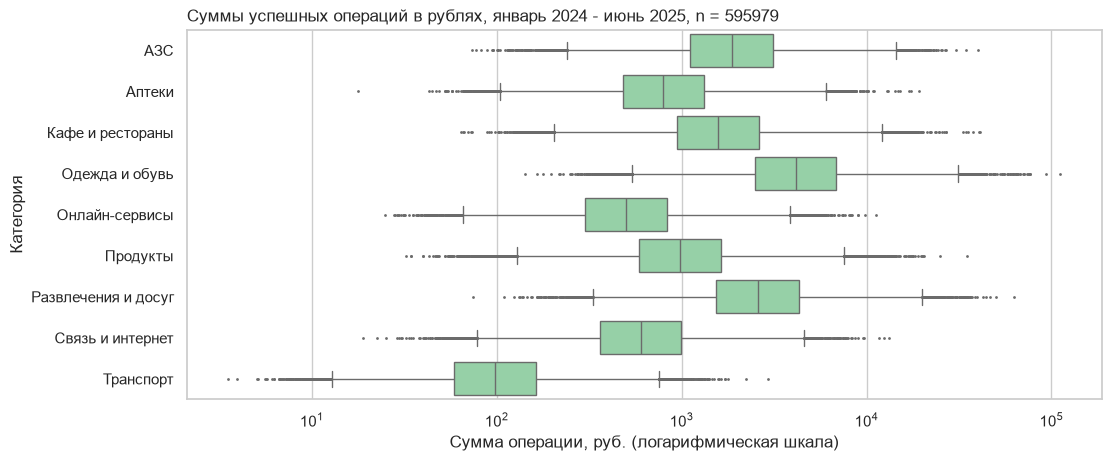

,"граница снизу, руб.",мелких,"самая мелкая, руб.","граница сверху, руб.",крупных,"самая крупная, руб."
АЗС,238.93,200,73.78,14476.15,154,39812.49
Аптеки,104.50,166,17.67,6051.55,138,19286.71
Кафе и рестораны,203.69,313,63.93,12081.21,235,41107.79
Одежда и обувь,540.38,258,142.56,31402.10,193,111303.87
Онлайн-сервисы,65.49,166,24.93,3848.00,164,11176.66
Продукты,128.06,625,32.47,7553.43,553,34724.35
Развлечения и досуг,330.64,180,74.37,20031.69,171,62986.40
Связь и интернет,78.23,208,18.96,4579.86,135,13208.19
Транспорт,12.78,218,3.54,752.63,210,2920.53


Пять самых крупных операций, в сыром файле записаны с теми же суммами: 5 из 5


txn_id,client_id,txn_datetime,amount,category,channel
158226,C002026,2024-02-28 16:19:58,111303.870000,Одежда и обувь,Карта
447607,C004094,2024-10-21 19:12:01,93570.360000,Одежда и обувь,Карта
261780,C001156,2024-05-25 08:03:00,76945.440000,Одежда и обувь,Карта
647228,C003403,2025-04-17 08:18:02,76509.890000,Одежда и обувь,СБП
276289,C004689,2024-06-06 15:45:38,75841.470000,Одежда и обувь,Токен


In [42]:
ok_rub = txn[(txn["status"] == "успешно") & (txn["currency"] == "RUB")]
a = ok_rub["amount"]
print("Операций со статусом \"успешно\" в рублях:", len(a))
print(f"Асимметрия amount: {a.skew():.2f}; среднее {a.mean():.0f} руб., медиана {a.median():.0f} руб.")

q1, q3 = a.quantile([0.25, 0.75])
lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
print(f"Q1 = {q1:.0f} руб., Q3 = {q3:.0f} руб., IQR = {q3 - q1:.0f} руб.")
print(f"Границы: снизу {lower:.0f} руб., сверху {upper:.0f} руб.")
print("Ниже нижней границы:", (a < lower).sum(), "| выше верхней:", share((a > upper).sum(), len(a)), "операций")


def log_bounds(s):
    log_s = np.log10(s)
    q1, q3 = log_s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return pd.Series({"граница снизу, руб.": 10 ** (q1 - 1.5 * iqr), "граница сверху, руб.": 10 ** (q3 + 1.5 * iqr)})


bounds = ok_rub.groupby("category", observed=True)["amount"].apply(log_bounds).unstack()
bounds.index = bounds.index.astype(str)
category = ok_rub["category"].astype(str)
too_small = a < category.map(bounds["граница снизу, руб."])
too_large = a > category.map(bounds["граница сверху, руб."])
side = pd.Series(np.select([too_small, too_large], ["мелкая", "крупная"], ""), index=ok_rub.index)
amount_flag = side != ""
print("На лог-шкале внутри своей категории за границами:", share(amount_flag.sum(), len(a)), "операций")
print("Из них слишком мелких:", too_small.sum(), "| слишком крупных:", too_large.sum())

fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
sns.boxplot(data=ok_rub, x="amount", y="category", log_scale=True, fliersize=1, color="#8DD9A3", ax=ax)
ax.set_xlabel("Сумма операции, руб. (логарифмическая шкала)")
ax.set_ylabel("Категория")
ax.set_title(f"Суммы успешных операций в рублях, январь 2024 - июнь 2025, n = {len(ok_rub)}", loc="left")
plt.show()

small, large = ok_rub[too_small], ok_rub[too_large]
by_category = bounds.assign(
    мелких=small.groupby(small["category"].astype(str)).size(),
    **{"самая мелкая, руб.": small.groupby(small["category"].astype(str))["amount"].min()},
    крупных=large.groupby(large["category"].astype(str)).size(),
    **{"самая крупная, руб.": large.groupby(large["category"].astype(str))["amount"].max()},
)
display(by_category[["граница снизу, руб.", "мелких", "самая мелкая, руб.",
                     "граница сверху, руб.", "крупных", "самая крупная, руб."]].round(2).rename_axis(index=None))

top5 = ok_rub.nlargest(5, "amount")
same_in_raw = txn_df[["txn_id", "amount"]].drop_duplicates().merge(top5[["txn_id", "amount"]], on=["txn_id", "amount"])
print("Пять самых крупных операций, в сыром файле записаны с теми же суммами:", same_in_raw["txn_id"].nunique(), "из 5")
top5[["txn_id", "client_id", "txn_datetime", "amount", "category", "channel"]].style.hide(axis="index")

Посмотрим на число операций у клиента за месяц, доход и возраст

In [43]:
ok_all = txn[txn["status"] == "успешно"]
per_month = ok_all.groupby(["client_id", ok_all["txn_datetime"].dt.to_period("M")]).size()
display(per_month.describe().round(1).to_frame("операций у клиента за месяц (месяцы с операциями)").T)

top_id, top_month = per_month.idxmax()
top = ok_all[(ok_all["client_id"] == top_id) & (ok_all["txn_datetime"].dt.to_period("M") == top_month)]
print(f"Больше всего операций за месяц: {len(top)} - у клиента {top_id} в {top_month.strftime('%m.%Y')}; "
      f"разных дней - {top['txn_datetime'].dt.date.nunique()}, категорий - {top['category'].nunique()}, "
      f"медиана суммы {top['amount'].median():.0f} ₽")

display(clients.groupby("segment", observed=True)["monthly_income"].describe().round(0))
print(f"Возраст: от {clients['age'].min()} до {clients['age'].max()} лет")

,count,mean,std,min,25%,50%,75%,max
операций у клиента за месяц (месяцы с операциями),92620.0,6.5,4.8,1.0,3.0,5.0,9.0,99.0


Больше всего операций за месяц: 99 - у клиента C004358 в 04.2025; разных дней - 28, категорий - 9, медиана суммы 1392 ₽


,count,mean,std,min,25%,50%,75%,max
segment,,,,,,,,
Private,204.0,366760.0,131977.0,94600.0,264150.0,347300.0,453925.0,791700.0
Зарплатный,1452.0,83039.0,32523.0,23700.0,59475.0,77250.0,99725.0,279900.0
Массовый,2568.0,64864.0,26188.0,14100.0,46200.0,60000.0,78700.0,246700.0
Премиальный,865.0,159545.0,63656.0,44600.0,112400.0,147000.0,195600.0,482900.0


Возраст: от 21 до 88 лет


Что видно:

- Берём `amount` у 595979 операций со статусом "успешно" в рублях. Асимметрия 5.04, среднее 1893 руб. при медиане 1093 руб., т.е. длинный правый хвост
- Классическое правило даёт границы от -2192 до 4967 руб. (Q1 = 493 руб., Q3 = 2282 руб., IQR = 1790 руб.). Нижняя граница отрицательная, ниже неё ни одной операции, т.е. мелкие аномалии это правило вообще не видит. А выше верхней 47666 операций (8.0%), но это не аномалии, а сам хвост - правило рассчитано на симметричные данные
- На логарифмической шкале у каждой категории свои границы, например в транспорте от 12.78 до 752.63 руб., в одежде от 540.38 до 31402.10 руб. За границами остаются 4287 операций (0.7%)
- Из них 2334 слишком мелкие: самая мелкая сумма в категории от 3.54 руб. в транспорте до 142.56 руб. в одежде. Это мелкие покупки, поездки и подписки, суммы маленькие, но возможные
- Ещё 1953 слишком крупные. Пять самых крупных, до 111304 руб., все в "Одежде и обуви", у разных клиентов и в разные даты, и в сыром файле записаны с теми же суммами, т.е. это правдоподобные покупки
- На графике точки за "усами" идут плотно сразу за ними и дальше редеют, т.е. это продолжение хвоста, а не отдельная группа в стороне, как было бы при ошибке единиц
- Операций в месяц (92620 месяцев, в которых у клиента были операции): медиана 5, максимум 99 у клиента C004358 в апреле 2025 года, в 28 разных днях и 9 категориях, медиана суммы 1392 руб. Это активный клиент, а не задвоение
- Доход после исправления единиц от 14100 до 791700 руб. (5089 клиентов), максимум в Private, где медиана 347300 руб.
- Возраст от 21 до 88 лет (5658 клиентов), правдоподобно

**Шаг 2 - решение** 

Ничего не удаляем и не меняем. Крупные суммы правдоподобны: самые большие это покупки одежды у разных клиентов в разные даты, и в сыром файле они записаны так же. Мелкие суммы тоже возможны: поездки, мелкие покупки, подписки. На графике это продолжение хвоста, а не отдельная группа, т.е. признаков ошибки нет, и удалив их, мы выбросили бы настоящие покупки. Операции у самого активного клиента разнесены по 28 дням и 9 категориям, это поведение, а не задвоение. Операции за границами помечаем флагом amount_outlier и записываем решение в журнал. Если суммы понадобятся в расчётах, по флагу можно будет проверить, меняют ли кандидаты результат

In [44]:
txn["amount_outlier"] = False
txn.loc[amount_flag.index, "amount_outlier"] = amount_flag
log_change("amount", "сумма за границей 1.5·IQR (лог-шкала, внутри категории)",
           "успешные операции в RUB, флаг amount_outlier", amount_flag.sum(), f"до {a.max():.0f} ₽",
           "оставлено, флаг amount_outlier", "без изменений",
           "крупные суммы правдоподобны для своих категорий и совпадают с сырым файлом; "
           "по флагу можно проверить, меняют ли кандидаты расчёты по суммам")
print("Помечено флагом amount_outlier:", share(txn["amount_outlier"].sum(), len(txn)), "операций")

Помечено флагом amount_outlier: 4287 из 617908 (0.7%) операций


### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [45]:
txn["month"] = txn["txn_datetime"].dt.to_period("M").dt.to_timestamp()
txn["period"] = np.where(txn["txn_datetime"] < EVAL_START, "base", "eval")
txn["in_directory"] = txn["client_id"].isin(clients["client_id"])

ok = txn[txn["in_directory"] & (txn["status"] == "успешно")]
funnel_txn.append(("клиент есть в справочнике действующих", int(txn["in_directory"].sum())))
funnel_txn.append(("статус \"успешно\"", len(ok)))

full_window = clients["card_open_date"] < BASE_START
funnel_clients.append(("карта открыта до 2024-01-01", int(full_window.sum())))

MIN_BASE_OPS = 12
ops_base = ok[ok["period"] == "base"].groupby("client_id").size()
active_base = clients["client_id"].map(ops_base).fillna(0) >= MIN_BASE_OPS
universe = clients[full_window & active_base].copy()
funnel_clients.append((f"не меньше {MIN_BASE_OPS} успешных операций в 2024 году", len(universe)))

ok_universe = ok[ok["client_id"].isin(universe["client_id"])].copy()
funnel_txn.append(("клиент входит в расчёт активности", len(ok_universe)))

log_change("client_id", "клиента нет в справочнике действующих: ушёл из банка",
           f"операции {txn.loc[~txn['in_directory'], 'client_id'].nunique()} client_id без профиля",
           (~txn["in_directory"]).sum(), "операции есть", "исключено из расчёта активности, в данных оставлено", "—",
           "профиля и согласия нет: обратиться к этим клиентам нельзя")
log_change("status", "операция отклонена или это возврат", "status ≠ \"успешно\"",
           (txn["in_directory"] & (txn["status"] != "успешно")).sum(), "отклонено, возврат",
           "исключено из расчёта активности, в данных оставлено", "—",
           "отклонённая операция не состоялась, а возврат отменяет покупку, а не добавляет новое использование карты")
log_change("card_open_date", "карта открыта в 2024–2025 годах: база 2024 года видна не целиком",
           "card_open_date ≥ 2024-01-01", (~full_window).sum(), "клиент в справочнике",
           "исключено из расчёта активности", "—",
           "операции видны только с даты открытия текущей карты (раздел 2.4); иначе клиент выглядит как рост \"с нуля\"")
log_change("client_id", f"меньше {MIN_BASE_OPS} успешных операций в 2024 году", f"операций в 2024 году < {MIN_BASE_OPS}",
           (full_window & ~active_base).sum(), "клиент в справочнике", "исключено из расчёта активности", "—",
           "при такой базе одна операция меняет сравнение 2025 года с 2024 на десятки процентов")

def show_funnel(steps):
    f = pd.DataFrame(steps, columns=["шаг", "осталось"])
    f["убрано"] = (-f["осталось"].diff()).fillna(0).astype(int)
    return f

print("Воронка клиентов:")
display(show_funnel(funnel_clients))
print("Воронка операций:")
display(show_funnel(funnel_txn))
print(f"Из {(~full_window).sum()} клиентов с картой, открытой в 2024–2025 годах, пришли в банк в эти же годы:",
      (clients.loc[~full_window, "registration_date"] >= BASE_START).sum())

login_before_reg = clients["app_last_login"].dt.to_period("M") < clients["registration_date"].dt.to_period("M")
print("Клиентов со входом в приложение раньше регистрации (2.1) в расчёте активности:",
      (login_before_reg & clients["client_id"].isin(universe["client_id"])).sum(), "из", login_before_reg.sum())

Воронка клиентов:


,шаг,осталось,убрано
0,сырой clients.csv,5713,0
1,без полных дублей,5671,42
2,одна строка на client_id,5658,13
3,карта открыта до 2024-01-01,4879,779
4,не меньше 12 успешных операций в 2024 году,4874,5


Воронка операций:


,шаг,осталось,убрано
0,сырой transactions.csv,619489,0
1,без полных дублей,618223,1266
2,одна строка на txn_id,617989,234
3,даты внутри 2024-01-01 … 2025-06-30,617908,81
4,клиент есть в справочнике действующих,588403,29505
5,"статус ""успешно""",569854,18549
6,клиент входит в расчёт активности,559397,10457


Из 779 клиентов с картой, открытой в 2024–2025 годах, пришли в банк в эти же годы: 137
Клиентов со входом в приложение раньше регистрации (2.1) в расчёте активности: 0 из 29


Воронка. Клиенты: 5713 -> 5658 после дублей -> 4879 после исключения 779 карт, открытых в 2024-2025 годах (из них 137 клиентов и пришли в банк в 2024-2025) -> 4874 после исключения 5 клиентов, у которых в 2024 году меньше 12 успешных операций. При такой базе сравнение 2025 года с 2024 неустойчиво, одна операция меняет его на десятки процентов. Ни один из 29 клиентов, у которых вход в приложение раньше регистрации (2.1), в расчёт не попал, поэтому эти даты не исправляем и оставляем как есть.

Операции: 619489 -> 617908 после дублей и дат вне периода -> 588403 у действующих клиентов (-29505 у ушедших) -> 569854 успешных (-18549 отклонённых и возвратов) -> 559397 у клиентов расчёта.

Почему только успешные: отклонённая операция не состоялась, а возврат это отмена покупки, а не новое использование карты.

## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [46]:
cleaning_log = pd.DataFrame(log_rows, columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

In [47]:
print("Решений в журнале:", len(cleaning_log))
with pd.option_context("display.max_colwidth", 80):
    display(cleaning_log)

Решений в журнале: 23


,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,все поля,полный дубль строки,"строки clients, повторяющиеся целиком",42,две одинаковые строки,удалено,одна строка,повтор выгрузки: одинаковые строки не несут новой информации и удваивают кли...
1,"city, segment",у одного client_id две версии профиля,"client_id: C000188, C000650, C000987, C002207, C002492, C002532, C003759, C0...",13,две строки с разными city или segment,"удалено (оставлена первая строка), флаг profile_conflict",одна строка на клиента,"какая версия верна, по данным установить нельзя; оставляем первую строку, а ..."
2,все поля,полный дубль строки,"строки transactions, повторяющиеся целиком",1266,две одинаковые операции,удалено,одна строка,повтор выгрузки: иначе операция посчитается в активности дважды
3,txn_datetime,одна операция записана дважды: с временем и без него,пары строк с одинаковым txn_id,234,2024-01-05 12:52:04 и 2024-01-05,удалено (оставлена запись с временем),одна строка на txn_id,остальные поля в парах совпадают (раздел 2.2); запись с временем полнее
4,"birth_date, registration_date, card_open_date, app_last_login","даты записаны текстом, у колонок разные форматы",все строки clients,5658,"""1982-07-23"", ""16.11.2021"", ""2024-10""","преобразовано в дату, у каждой колонки свой явный формат",datetime,явный формат не даёт перепутать день и месяц; ни одно значение не потерялось
5,txn_datetime,дата записана текстом в двух форматах: с временем и без,все строки transactions,617989,"""2024-01-05 12:52:04"" или ""2024-01-05""; строк без времени: 49444",преобразовано в дату и время; где времени нет — 00:00 и флаг time_missing,datetime,"для помесячной метрики достаточно даты; время не придумываем, а помечаем"
6,txn_datetime,дата раньше начала выгрузки,"txn_id 990048, 990003",2,2023-12-11,удалено,—,данные заявлены с 2024-01-01; эти операции не входят ни в одно окно анализа
7,txn_datetime,дата позже даты среза 30.06.2025,txn_datetime ≥ 2025-07-01,79,2025-07-04 … 2026-08-02,удалено,—,операций позже даты выгрузки быть не может: это ошибка даты
8,monthly_income,код-заглушка -999 вместо дохода,monthly_income == -999,44,-999.0,заменено на пропуск,NaN,"отрицательного дохода не бывает: это служебный код ""нет данных"""
9,monthly_income,доход записан в тысячах рублей,0 < monthly_income < 1000,124,24.5 … 499.8,исправлено: × 1000,24500 … 499800,медианы этих значений × 1000 совпадают по порядку с медианами дохода в своём...


## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

Клиентские признаки описываем по всему очищенному справочнику (5658 клиентов), а операции по успешным операциям действующих клиентов. Динамику и разрезы считаем на клиентах, у которых базовый период виден целиком (раздел 3.5), иначе рост "с нуля" у новых карт смешается с падением.

### 5.1. Распределения количественных признаков

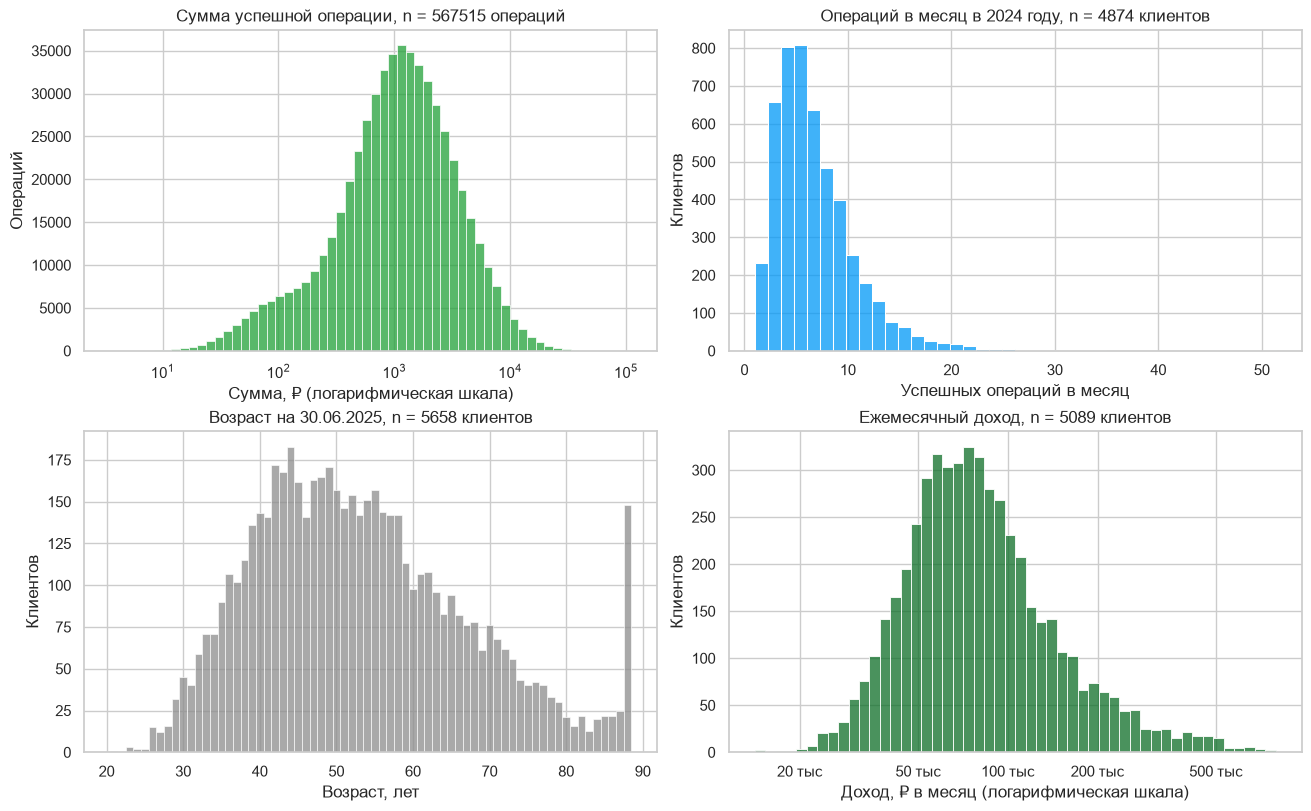

In [48]:
ok_rub = ok[ok["currency"] == "RUB"]
base_opm = ok_universe[ok_universe["period"] == "base"].groupby("client_id").size() / BASE_MONTHS
income = clients["monthly_income"].dropna()

fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained")
sns.histplot(ok_rub["amount"], bins=60, log_scale=True, color="#21A038", ax=axes[0, 0])
axes[0, 0].set(title=f"Сумма успешной операции, n = {len(ok_rub)} операций",
               xlabel="Сумма, ₽ (логарифмическая шкала)", ylabel="Операций")
sns.histplot(base_opm, bins=40, color="#0098F8", ax=axes[0, 1])
axes[0, 1].set(title=f"Операций в месяц в 2024 году, n = {len(base_opm)} клиентов",
               xlabel="Успешных операций в месяц", ylabel="Клиентов")
sns.histplot(clients["age"], discrete=True, color="#8C8C8C", ax=axes[1, 0])   # один столбик на каждый год
axes[1, 0].set(title=f"Возраст на 30.06.2025, n = {len(clients)} клиентов", xlabel="Возраст, лет", ylabel="Клиентов")
sns.histplot(income, bins=50, log_scale=True, color="#0D6E27", ax=axes[1, 1])
axes[1, 1].set(title=f"Ежемесячный доход, n = {len(income)} клиентов",
               xlabel="Доход, ₽ в месяц (логарифмическая шкала)", ylabel="Клиентов")
axes[1, 1].set_xticks([20_000, 50_000, 100_000, 200_000, 500_000], ["20 тыс", "50 тыс", "100 тыс", "200 тыс", "500 тыс"])
axes[1, 1].minorticks_off()
plt.show()

На гистограмме возраста в правом конце, около 88 лет, заметный пик. Посмотрим, сколько клиентов в каждом возрасте от 79 лет

In [49]:
top_age = clients["age"].max()
print(f"Клиентов в возрасте {top_age} лет:", share((clients["age"] == top_age).sum(), len(clients)))
clients["age"].value_counts().sort_index().tail(10).to_frame("клиентов").T.rename_axis(columns=None)

Клиентов в возрасте 88 лет: 148 из 5658 (2.6%)


,79,80,81,82,83,84,85,86,87,88
клиентов,30,21,16,22,13,20,22,22,25,148


В возрасте 88 лет 148 клиентов из 5658 (2.6%), а в каждом возрасте от 80 до 87 от 13 до 25. Похоже, возраст старше 88 записан как 88, т.е. обрезан сверху, и точный возраст самых старших клиентов в данных не виден. Медиана и квартили возраста от этого не меняются, а среднее может быть немного занижено. Исправить это нечем, оставляем как есть

In [50]:
def describe_num(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({"n": s.count(), "среднее": s.mean(), "медиана": s.median(), "ст. откл.": s.std(),
                      "Q1": q1, "Q3": q3, "IQR": q3 - q1, "асимметрия": s.skew()})


pd.DataFrame({
    "сумма операции, ₽": describe_num(ok_rub["amount"]),
    "операций в месяц, 2024": describe_num(base_opm),
    "возраст, лет": describe_num(clients["age"]),
    "доход, ₽ в месяц": describe_num(income),
}).T.round(2)

,n,среднее,медиана,ст. откл.,Q1,Q3,IQR,асимметрия
"сумма операции, ₽",567515.0,1898.35,1095.34,2586.74,493.67,2289.74,1796.07,5.04
"операций в месяц, 2024",4874.0,6.83,5.92,4.02,4.08,8.67,4.58,1.96
"возраст, лет",5658.0,53.30,51.00,14.07,43.00,62.00,19.00,0.55
"доход, ₽ в месяц",5089.0,98244.82,75200.00,78668.45,54300.00,110000.00,55700.00,3.23


In [51]:
sat = clients["satisfaction_score"].dropna()
print("Оценку поставили:", share(len(sat), len(clients)), "клиентов")
print(f"Медиана {sat.median():.0f}, мода {sat.mode()[0]}, Q1–Q3: {sat.quantile(0.25):.0f}–{sat.quantile(0.75):.0f}")
counts = sat.value_counts().sort_index()
pd.DataFrame({"клиентов": counts, "доля ответивших, %": (counts / len(sat) * 100).round(1)}).T

Оценку поставили: 2275 из 5658 (40.2%) клиентов
Медиана 3, мода 5, Q1–Q3: 2–5


satisfaction_score,1,2,3,4,5
клиентов,248,426,493,479,629
"доля ответивших, %",10.9,18.7,21.7,21.1,27.6


Выбор мер центра и разброса зависит от формы распределения:

- Сумма операции: асимметрия 5.04, среднее 1898 руб. при медиане 1095 руб., т.е. среднее тянет хвост. Описываем медианой и IQR
- Операций в месяц у клиента в 2024 году: асимметрия 1.96, медиана 5.92, IQR 4.58, тоже медиана и IQR
- Возраст: распределение почти симметричное (асимметрия 0.55), среднее 53.3 и медиана 51 близки, поэтому допустимы среднее и стандартное отклонение (14.07 года)
- Доход: асимметрия 3.23, поэтому медиана 75200 руб. и IQR 55700 руб. (5089 клиентов без пропусков)
- `satisfaction_score` это порядковая шкала, расстояние между "2" и "3" не обязано равняться расстоянию между "4" и "5", поэтому среднее не считаем. Ответили 2275 из 5658 (40.2%), медиана 3, мода 5, Q1-Q3 от 2 до 5, т.е. оценки разбросаны по всей шкале

### 5.2. Частотные характеристики категориальных признаков

In [52]:
def freq(s):
    counts = s.value_counts(dropna=False)
    return pd.DataFrame({"n": counts, "доля, %": (counts / len(s) * 100).round(1)}).T


YES_NO_LABEL = {True: "да", False: "нет"}
for col in ["segment", "loyalty_tier", "card_type", "city", "income_source", "gender",
            "has_mobile_app", "marketing_opt_in"]:
    values = clients[col].map(YES_NO_LABEL) if clients[col].dtype == bool else clients[col]
    print(f"{col}, доли от {len(clients)} клиентов:")
    display(freq(values))
for col in ["category", "channel", "status", "currency"]:
    print(f"{col}, доли от {len(txn)} операций:")
    display(freq(txn[col]))

segment, доли от 5658 клиентов:


segment,Массовый,Зарплатный,Премиальный,Private
n,2949.0,1541.0,943.0,225.0
"доля, %",52.1,27.2,16.7,4.0


loyalty_tier, доли от 5658 клиентов:


loyalty_tier,Базовый,Серебро,Золото,Платина
n,2854.0,1541.0,964.0,299.0
"доля, %",50.4,27.2,17.0,5.3


card_type, доли от 5658 клиентов:


card_type,Дебетовая,Кредитная,Премиальная
n,3898.0,1252.0,508.0
"доля, %",68.9,22.1,9.0


... (14 outputs left out)

status, доли от 617908 операций:


status,успешно,отклонено,возврат
n,598424.0,12052.0,7432.0
"доля, %",96.8,2.0,1.2


currency, доли от 617908 операций:


currency,RUB,USD,EUR
n,615374.0,1271.0,1263.0
"доля, %",99.6,0.2,0.2


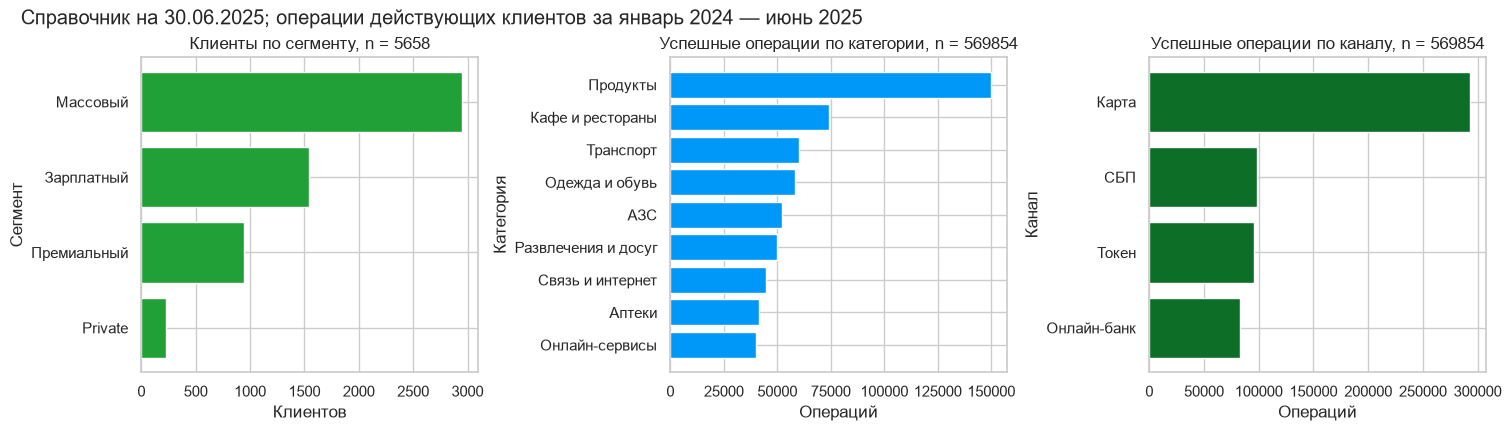

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), layout="constrained")
seg = clients["segment"].value_counts().sort_values()
axes[0].barh(seg.index.astype(str), seg.values, color="#21A038")
axes[0].set(title=f"Клиенты по сегменту, n = {len(clients)}", xlabel="Клиентов", ylabel="Сегмент")
cat = ok["category"].value_counts().sort_values()
axes[1].barh(cat.index.astype(str), cat.values, color="#0098F8")
axes[1].set(title=f"Успешные операции по категории, n = {len(ok)}", xlabel="Операций", ylabel="Категория")
chan = ok["channel"].value_counts().sort_values()
axes[2].barh(chan.index.astype(str), chan.values, color="#0D6E27")
axes[2].set(title=f"Успешные операции по каналу, n = {len(ok)}", xlabel="Операций", ylabel="Канал")
fig.suptitle("Справочник на 30.06.2025; операции действующих клиентов за январь 2024 — июнь 2025", x=0.01, ha="left")
plt.show()

Посмотрим на связи между клиентскими признаками. Проценты по строке, последняя колонка - сколько клиентов в строке

In [54]:
APP_LABEL = {True: "есть приложение", False: "нет приложения"}
for col in ["has_mobile_app", "loyalty_tier", "card_type", "income_source"]:
    values = clients[col].map(APP_LABEL) if col == "has_mobile_app" else clients[col]
    ct = pd.crosstab(clients["segment"], values, normalize="index").round(3) * 100
    ct["n клиентов"] = clients["segment"].value_counts()
    print(f"Сегмент × {col}: % клиентов в строке")
    display(ct)
ct = pd.crosstab(clients["city"], clients["segment"], normalize="index").round(3) * 100
ct["n клиентов"] = clients["city"].value_counts()
print("Город × сегмент: % клиентов в строке")
ct

Сегмент × has_mobile_app: % клиентов в строке


has_mobile_app,есть приложение,нет приложения,n клиентов
segment,,,
Private,55.1,44.9,225
Зарплатный,60.2,39.8,1541
Массовый,61.5,38.5,2949
Премиальный,60.3,39.7,943


Сегмент × loyalty_tier: % клиентов в строке


loyalty_tier,Базовый,Серебро,Золото,Платина,n клиентов
segment,,,,,
Private,4.4,10.7,38.2,46.7,225
Зарплатный,44.6,35.5,17.1,2.8,1541
Массовый,69.8,21.4,7.8,1.0,2949
Премиальный,10.6,35.8,40.7,12.8,943


Сегмент × card_type: % клиентов в строке


card_type,Дебетовая,Кредитная,Премиальная,n клиентов
segment,,,,
Private,17.3,14.2,68.4,225
Зарплатный,71.6,26.3,2.0,1541
Массовый,79.3,19.5,1.2,2949
Премиальный,44.2,25.3,30.4,943


Сегмент × income_source: % клиентов в строке


income_source,Зарплата в другом банке,Зарплата в нашем банке,Не указан,n клиентов
segment,,,,
Private,39.6,30.7,29.8,225
Зарплатный,7.1,88.0,4.9,1541
Массовый,33.8,24.8,41.4,2949
Премиальный,37.3,37.5,25.1,943


Город × сегмент: % клиентов в строке


segment,Private,Зарплатный,Массовый,Премиальный,n клиентов
city,,,,,
Екатеринбург,3.9,32.6,45.6,17.9,691
Казань,5.0,32.4,45.3,17.2,697
Москва,3.9,30.9,45.3,20.0,1609
Нижний Новгород,1.0,7.1,87.6,4.2,966
Новосибирск,4.8,31.1,45.4,18.7,691
Санкт-Петербург,5.8,30.8,42.7,20.7,1004


Что видно (знаменатель 5658 клиентов или 617908 операций):

- Массовый сегмент больше половины клиентов: 2949 (52.1%), Зарплатный 27.2%, Премиальный 16.7%, Private 4.0%
- Приложение есть у 60.7% клиентов, согласие на маркетинг у 4952 (87.5%)
- В операциях больше всего "Продуктов" (26.3%), канал "Карта" 51.4%, успешных 96.8%, в рублях 99.6%
- Лояльность почти повторяет сегмент: в Массовом 69.8% "Базовый", в Private 46.7% "Платина", т.е. эти признаки во многом дублируют друг друга
- Тип карты тоже связан с сегментом: премиальная карта у 68.4% клиентов Private и у 30.4% Премиального, а в Массовом у 1.2%
- Источник зарплаты: в Зарплатном сегменте у 88.0% зарплата в нашем банке, в Массовом у 41.4% источник не указан
- Приложение от сегмента почти не зависит: оно есть у 55.1-61.5% клиентов каждого сегмента
- Нижний Новгород на 87.6% состоит из клиентов Массового сегмента, остальные города на 42.7-45.6%

### 5.3. Динамика по месяцам

Посмотрим, как меняется число успешных операций по месяцам в каждом сегменте. Сегменты разного размера, поэтому считаем операции на одного клиента

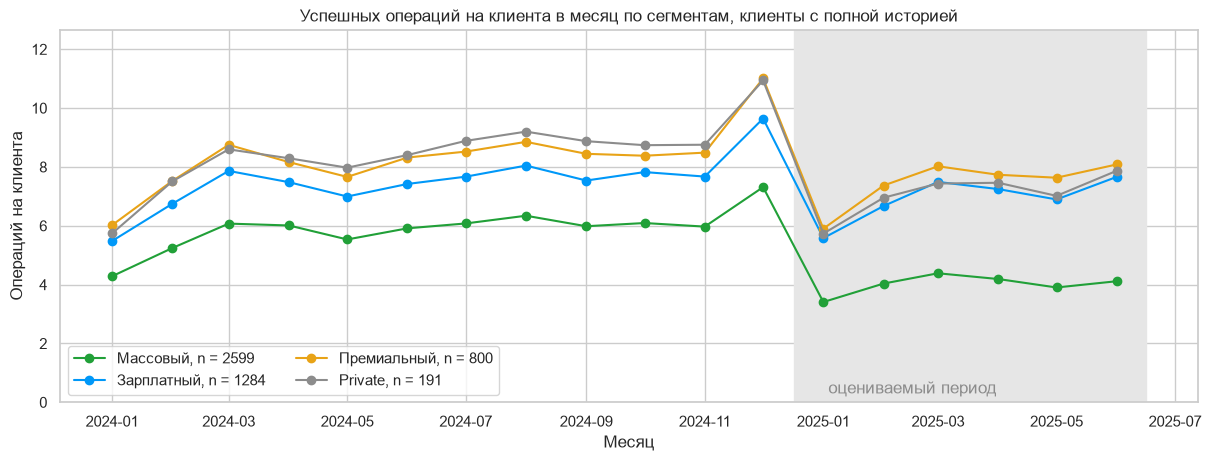

,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01,2024-10-01,2024-11-01,2024-12-01,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01
Массовый,4.28,5.24,6.07,6.01,5.53,5.91,6.08,6.34,5.98,6.09,5.97,7.31,3.41,4.04,4.38,4.19,3.90,4.11
Зарплатный,5.48,6.75,7.86,7.48,6.99,7.42,7.67,8.05,7.54,7.82,7.67,9.64,5.58,6.67,7.49,7.25,6.89,7.66
Премиальный,6.02,7.52,8.75,8.16,7.66,8.32,8.52,8.85,8.44,8.38,8.48,11.01,5.90,7.37,8.02,7.73,7.63,8.08
Private,5.74,7.51,8.60,8.29,7.97,8.40,8.88,9.20,8.87,8.74,8.75,10.94,5.73,6.95,7.43,7.46,7.02,7.87


In [55]:
segment_of = universe.set_index("client_id")["segment"]
segment_size = segment_of.value_counts()

monthly = ok_universe.groupby(["month", ok_universe["client_id"].map(segment_of).rename("segment")],
                              observed=True).size().unstack()
per_client = (monthly / segment_size)[segment_size.index]

fig, ax = plt.subplots(figsize=(12, 4.5), layout="constrained")
for seg, color in zip(segment_size.index, ["#21A038", "#0098F8", "#E8A317", "#8C8C8C"]):
    ax.plot(per_client.index, per_client[seg], marker="o", color=color, label=f"{seg}, n = {segment_size[seg]}")
ax.axvspan(EVAL_START - pd.Timedelta(days=15), per_client.index.max() + pd.Timedelta(days=15), color="#E6E6E6")
ax.text(EVAL_START, 0.3, " оцениваемый период", color="#8C8C8C")
ax.set(title="Успешных операций на клиента в месяц по сегментам, клиенты с полной историей",
       xlabel="Месяц", ylabel="Операций на клиента")
ax.set_ylim(0, per_client.max().max() * 1.15)
ax.legend(loc="lower left", ncols=2)
plt.show()
per_client.T.round(2).rename_axis(index=None, columns=None)

Что видно:

- У Массового сегмента с января 2025 года операций на клиента меньше, чем в те же месяцы 2024 года: в январе 3.41 против 4.28, в июне 4.11 против 5.91
- У Зарплатного, Премиального и Private 2025 год почти повторяет 2024: в январе 5.58 против 5.48, 5.90 против 6.02 и 5.73 против 5.74
- У всех сегментов январь 2024 года самый низкий месяц года, а декабрь 2024 года самый высокий, т.е. есть сезонность

Базовый период это весь 2024 год, а оцениваемый только январь-июнь 2025, т.е. окна разной длины. Посчитаем, насколько январь-июнь отличается от среднего месяца года

In [56]:
total = ok_universe.groupby("month").size()
base_avg = total[total.index < EVAL_START].mean()
h1_2024 = total[total.index < H1_2024_END].mean()
SEASONAL_NORM = h1_2024 / base_avg
print(f"Средний месяц января-июня 2024 года - {SEASONAL_NORM:.2f} от среднего месяца 2024 года")
print(f"Декабрь 2024 года - {total[pd.Timestamp('2024-12-01')] / base_avg:.2f}, "
      f"январь 2024 года - {total[pd.Timestamp('2024-01-01')] / base_avg:.2f} от среднего месяца 2024 года")

Средний месяц января-июня 2024 года - 0.93 от среднего месяца 2024 года
Декабрь 2024 года - 1.27, январь 2024 года - 0.72 от среднего месяца 2024 года


Сезонность сильная: январь 2024 года 0.72 от среднего месяца, декабрь 1.27, а январь-июнь в среднем 0.93. Значит даже если в поведении клиентов ничего не изменилось, средний месяц января-июня составляет около 0.93 среднего месяца года, а не 1. Поэтому дальше сравниваем январь-июнь 2025 года с январём-июнем 2024

Посмотрим на каналы оплаты по месяцам

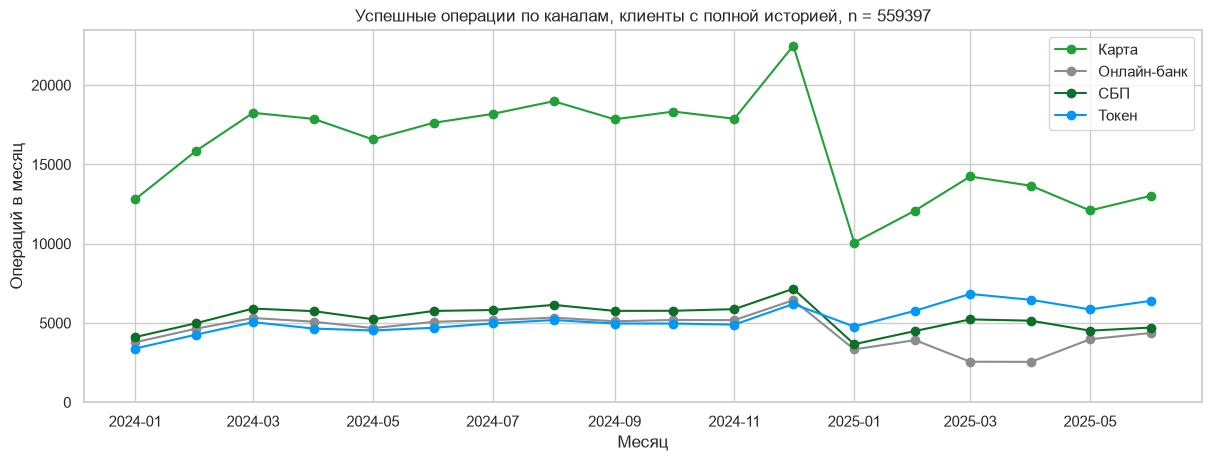

Январь-июнь 2025 к январю-июню 2024: Карта -24.1%, Онлайн-банк -27.5%, СБП -12.6%, Токен +35.8%


,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01,2024-10-01,2024-11-01,2024-12-01,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01
Карта,12798,15852,18252,17865,16573,17624,18184,18983,17842,18331,17879,22489,10067,12090,14236,13652,12094,13020
Онлайн-банк,3783,4640,5312,5080,4675,5073,5179,5338,5109,5189,5179,6439,3335,3918,2558,2548,3972,4370
СБП,4112,4985,5908,5745,5238,5759,5818,6141,5762,5770,5871,7157,3661,4494,5225,5143,4516,4712
Токен,3390,4265,5050,4647,4528,4699,4975,5185,4966,4963,4898,6198,4772,5772,6830,6459,5857,6398


In [57]:
by_channel = ok_universe.groupby(["month", "channel"], observed=True).size().unstack()

fig, ax = plt.subplots(figsize=(12, 4.5), layout="constrained")
for ch, color in zip(by_channel.columns, ["#21A038", "#8C8C8C", "#0D6E27", "#0098F8"]):
    ax.plot(by_channel.index, by_channel[ch], marker="o", label=str(ch), color=color)
ax.set(title=f"Успешные операции по каналам, клиенты с полной историей, n = {len(ok_universe)}",
       xlabel="Месяц", ylabel="Операций в месяц")
ax.set_ylim(0, None)
ax.legend()
plt.show()

first_half = ok_universe[ok_universe["txn_datetime"] < H1_2024_END].groupby("channel", observed=True).size()
eval_half = ok_universe[ok_universe["txn_datetime"] >= EVAL_START].groupby("channel", observed=True).size()
print("Январь-июнь 2025 к январю-июню 2024:", ", ".join(f"{ch} {v:+.1%}" for ch, v in (eval_half / first_half - 1).items()))

by_channel.T.rename_axis(index=None, columns=None)

Что видно:

- За январь-июнь 2025 года к январю-июню 2024 вырос только "Токен" (+35.8%), "Карта" -24.1%, онлайн-банк -27.5%, СБП -12.6%
- У онлайн-банка в марте-апреле 2025 года операций почти вдвое меньше, чем годом раньше: 2558 и 2548 против 5312 и 5080, а в мае-июне снова больше, 3972 и 4370. У других каналов в марте-апреле такого провала нет

Проверим, у всех ли сегментов провал онлайн-банка или только у части клиентов

In [58]:
online = ok_universe[ok_universe["channel"] == "Онлайн-банк"]

def march_april(year):
    window = (online["txn_datetime"] >= f"{year}-03-01") & (online["txn_datetime"] < f"{year}-05-01")
    return online[window]["client_id"].map(segment_of).value_counts()

dip = march_april(2025) / march_april(2024) - 1
print("Онлайн-банк, март-апрель 2025 к марту-апрелю 2024:", ", ".join(f"{seg} {v:+.1%}" for seg, v in dip.items()))

Онлайн-банк, март-апрель 2025 к марту-апрелю 2024: Массовый -58.0%, Зарплатный -41.4%, Премиальный -48.4%, Private -49.2%


Провал есть во всех сегментах: от -41.4% у Зарплатного до -58.0% у Массового. Значит это не поведение отдельной группы клиентов, а что-то общее для этого канала: провал у всех сразу и только в онлайн-банке. Что именно случилось, сбой канала или неполная выгрузка, по данным не установить

Посмотрим на сумму операции по месяцам, падать может не только число операций, но и их сумма. Берём медиану, потому что у сумм длинный правый хвост, и только рубли, потому что курсов валют в данных нет

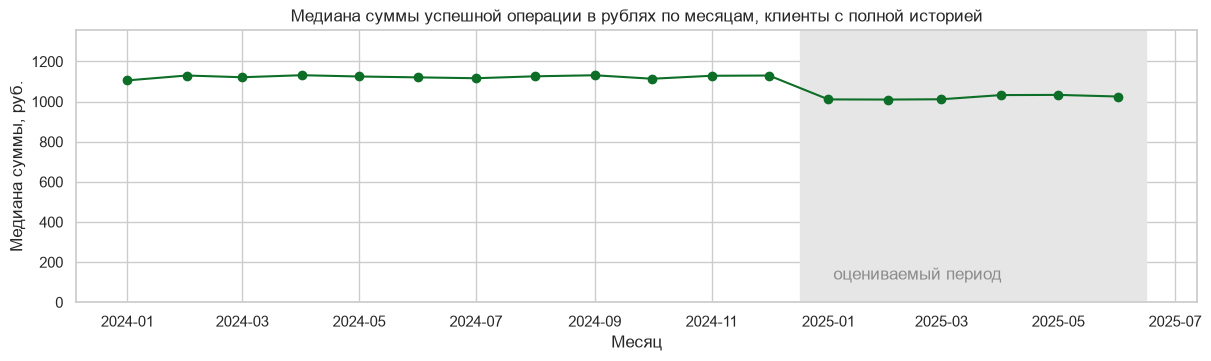

,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01,2024-10-01,2024-11-01,2024-12-01,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01
"медиана, руб.",1106.0,1130.0,1121.0,1132.0,1125.0,1121.0,1117.0,1126.0,1131.0,1114.0,1129.0,1130.0,1011.0,1010.0,1012.0,1033.0,1033.0,1025.0


In [59]:
rub = ok_universe[ok_universe["currency"] == "RUB"].join(segment_of, on="client_id")
ticket = rub.groupby("month")["amount"].median()

fig, ax = plt.subplots(figsize=(12, 3.5), layout="constrained")
ax.plot(ticket.index, ticket.values, marker="o", color="#0D6E27")
ax.axvspan(EVAL_START - pd.Timedelta(days=15), ticket.index.max() + pd.Timedelta(days=15), color="#E6E6E6")
ax.text(EVAL_START, ticket.max() * 0.1, " оцениваемый период", color="#8C8C8C")
ax.set(title="Медиана суммы успешной операции в рублях по месяцам, клиенты с полной историей",
       xlabel="Месяц", ylabel="Медиана суммы, руб.")
ax.set_ylim(0, ticket.max() * 1.2)
plt.show()
ticket.round(0).to_frame("медиана, руб.").T.rename_axis(columns=None)

В 2024 году медиана держится на уровне 1106-1132 руб., а с января 2025 года опускается до 1010-1033 руб. и обратно не возвращается. Сравним одинаковые месяцы двух лет и проверим, есть ли снижение во всех категориях и сегментах и не дают ли его кандидаты в выбросы

In [60]:
rub_h1_2024 = rub[rub["txn_datetime"] < H1_2024_END]
rub_h1_2025 = rub[rub["txn_datetime"] >= EVAL_START]
med_24, med_25 = rub_h1_2024["amount"].median(), rub_h1_2025["amount"].median()
print(f"Медиана суммы: январь-июнь 2024 {med_24:.0f} руб., январь-июнь 2025 {med_25:.0f} руб. ({med_25 / med_24 - 1:+.1%})")

def median_change(by):
    t = pd.DataFrame({
        "январь-июнь 2024, руб.": rub_h1_2024.groupby(by, observed=True)["amount"].median(),
        "январь-июнь 2025, руб.": rub_h1_2025.groupby(by, observed=True)["amount"].median(),
    })
    t["изменение, %"] = (t["январь-июнь 2025, руб."] / t["январь-июнь 2024, руб."] - 1) * 100
    return t.round({"январь-июнь 2024, руб.": 0, "январь-июнь 2025, руб.": 0, "изменение, %": 1}).rename_axis(index=None)

print("По категориям:")
display(median_change("category"))
print("По сегментам:")
display(median_change("segment"))

no_outliers = rub[~rub["amount_outlier"]]
out_24 = no_outliers.loc[no_outliers["txn_datetime"] < H1_2024_END, "amount"].median()
out_25 = no_outliers.loc[no_outliers["txn_datetime"] >= EVAL_START, "amount"].median()
print(f"Без операций с флагом amount_outlier: {out_24:.0f} и {out_25:.0f} руб. ({out_25 / out_24 - 1:+.1%})")

Медиана суммы: январь-июнь 2024 1123 руб., январь-июнь 2025 1021 руб. (-9.1%)
По категориям:


,"январь-июнь 2024, руб.","январь-июнь 2025, руб.","изменение, %"
АЗС,1911.0,1748.0,-8.6
Аптеки,809.0,754.0,-6.7
Кафе и рестораны,1589.0,1490.0,-6.2
Одежда и обувь,4213.0,3934.0,-6.6
Онлайн-сервисы,517.0,481.0,-6.9
Продукты,1009.0,937.0,-7.1
Развлечения и досуг,2647.0,2424.0,-8.4
Связь и интернет,610.0,565.0,-7.5
Транспорт,100.0,93.0,-7.1


По сегментам:


,"январь-июнь 2024, руб.","январь-июнь 2025, руб.","изменение, %"
Private,2362.0,2142.0,-9.3
Зарплатный,1084.0,910.0,-16.0
Массовый,915.0,840.0,-8.3
Премиальный,1625.0,1485.0,-8.6


Без операций с флагом amount_outlier: 1123 и 1027 руб. (-8.5%)


За январь-июнь медиана суммы снизилась с 1123 до 1021 руб. (-9.1%). Снижение есть во всех девяти категориях, от -8.6% до -6.2%, и во всех сегментах, от -16.0% у Зарплатного до -8.3% у Массового. Без кандидатов в выбросы из 3.4 почти так же: 1123 и 1027 руб. (-8.5%), т.е. снижение не из-за выбросов. Значит суммы снизились у всех сегментов, а не только у Массового, где упало число операций

Итого по динамике (4874 клиента с полной историей):

- Число операций на клиента в 2025 году упало у Массового сегмента, у остальных январь-июнь 2025 почти повторяет 2024 год
- Сезонность сильная: январь-июнь 2024 года в среднем 0.93 среднего месяца года, поэтому сравниваем одинаковые месяцы
- Из каналов вырос только "Токен" (+35.8%)
- Провал онлайн-банка в марте-апреле 2025 года есть у всех сегментов
- Медиана суммы операции снизилась на 9.1%, во всех категориях и сегментах

### 5.4. Разрезы и связи между признаками

Сравним одинаковые месяцы: январь-июнь 2025 против января-июня 2024, так сезонность не искажает сравнение. Клиенты одни и те же, поэтому делить на число клиентов не нужно. Возьмём признаки клиента, которые задание называет для правил групп (сегмент, приложение, возраст, город, тип карты, лояльность), и источник зарплаты. Если зарплата приходит в другой банк, клиент мог перенести туда и траты

In [61]:
universe["age_group"] = pd.cut(universe["age"], [0, 30, 45, 60, 120], right=False,
                               labels=["до 30", "30-44", "45-59", "60+"])
ATTRS = ["segment", "has_mobile_app", "age_group", "city", "income_source", "card_type", "loyalty_tier"]
attrs = universe.set_index("client_id")[ATTRS]
okx = ok_universe.join(attrs, on="client_id")
okx["half"] = np.select(
    [okx["txn_datetime"] < H1_2024_END, okx["txn_datetime"] >= EVAL_START],
    ["H1_2024", "H1_2025"], "H2_2024")


def yoy(df, by):
    counts = df[df["half"] != "H2_2024"].groupby(by + ["half"], observed=True).size().unstack("half")
    return (counts["H1_2025"] / counts["H1_2024"] - 1) * 100


change = pd.concat({col: pd.DataFrame({"клиентов": attrs[col].value_counts(), "изменение, %": yoy(okx, [col])})
                    for col in ATTRS})
change.round(1).rename(index=APP_LABEL).rename_axis(index=[None, None])

клиентов  изменение, %
segment        Private                       191          -8.7
               Зарплатный                   1284          -1.1
               Массовый                     2599         -27.3
               Премиальный                   800          -3.7
has_mobile_app нет приложения               1950         -21.4
               есть приложение              2924          -9.6
age_group      до 30                          69          -3.2
               30-44                        1407          -9.6
               45-59                        1945         -14.9
               60+                          1453         -19.1
city           Екатеринбург                  595         -12.5
               Казань                        588         -11.9
               Москва                       1365         -12.0
               Нижний Новгород               846         -24.9
               Новосибирск                   599         -15.2
               Санкт-Петербург               881          -9.7
income_source  Зарплата в другом банке      1347         -17.7
               Зарплата в нашем банке       2132          -7.2
               Не указан                    1395         -22.1
card_type      Дебетовая                    3374         -15.9
               Кредитная                    1069         -13.0
               Премиальная                   431          -4.5
loyalty_tier   Базовый                      2500         -19.8
               Серебро                      1325         -14.0
               Золото                        787          -2.8
               Платина                       262          -2.4

Что видно:

- Сегмент: Массовый -27.3%, остальные от -8.7% у Private до -1.1% у Зарплатного
- Без приложения -21.4%, с приложением -9.6%
- Чем старше клиент, тем сильнее падение: от -3.2% до 30 лет до -19.1% у 60+
- Нижний Новгород -24.9%, остальные города от -15.2% до -9.7%
- Источник зарплаты: "Не указан" -22.1% и "Зарплата в другом банке" -17.7% против -7.2% у "Зарплата в нашем банке"
- Тип карты: "Премиальная" -4.5%, дебетовая и кредитная -15.9% и -13.0%
- Лояльность: "Базовый" -19.8%, "Серебро" -14.0%, "Золото" и "Платина" -2.8% и -2.4%

В 5.2 видно, что тип карты, лояльность, источник зарплаты и город связаны с сегментом, поэтому часть этих различий может быть просто различием сегментов. Зарплатный, Премиальный и Private падают мало, поэтому сравним каждый признак отдельно внутри Массового сегмента и внутри трёх остальных вместе

In [62]:
in_mass = okx["segment"] == "Массовый"
mass_clients = attrs[attrs["segment"] == "Массовый"]
within = pd.concat({col: pd.DataFrame({
    "все клиенты, %": yoy(okx, [col]),
    "Массовый, %": yoy(okx[in_mass], [col]),
    "остальные сегменты, %": yoy(okx[~in_mass], [col]),
    "клиентов в Массовом": mass_clients[col].value_counts(),
}) for col in ATTRS[1:]})
within.round(1).rename(index=APP_LABEL).rename_axis(index=[None, None])

все клиенты, %  Массовый, %  остальные сегменты, %  клиентов в Массовом
has_mobile_app нет приложения                    -21.4        -38.7                   -6.7                 1042
               есть приложение                    -9.6        -20.4                   -0.3                 1557
age_group      до 30                              -3.2        -14.1                    7.5                   43
               30-44                              -9.6        -20.4                   -0.9                  737
               45-59                             -14.9        -29.3                   -2.1                 1049
               60+                               -19.1        -33.6                   -6.6                  770
city           Екатеринбург                      -12.5        -27.2                   -1.8                  285
               Казань                            -11.9        -28.4                   -1.7                  275
               Москва                            -12.0        -26.1                   -3.0                  624
               Нижний Новгород                   -24.9        -28.4                   -5.6                  744
               Новосибирск                       -15.2        -33.8                   -3.0                  282
               Санкт-Петербург                    -9.7        -21.6                   -2.6                  389
income_source  Зарплата в другом банке           -17.7        -27.0                   -4.9                  887
               Зарплата в нашем банке             -7.2        -27.0                   -0.7                  636
               Не указан                         -22.1        -27.8                   -8.4                 1076
card_type      Дебетовая                         -15.9        -27.4                   -2.0                 2062
               Кредитная                         -13.0        -27.9                   -3.2                  507
               Премиальная                        -4.5        -10.4                   -4.2                   30
loyalty_tier   Базовый                           -19.8        -28.3                   -1.8                 1824
               Серебро                           -14.0        -29.3                   -5.8                  556
               Золото                             -2.8        -13.3                   -0.3                  192
               Платина                            -2.4        -19.3                   -1.2                   27

Что видно:

- Приложение: разница остаётся внутри сегментов. В Массовом без приложения -38.7%, с приложением -20.4%, в остальных сегментах -6.7% и -0.3%
- Возраст: внутри Массового тоже чем старше, тем сильнее падение, от -14.1% до 30 лет (всего 43 клиента) до -33.6% у 60+
- Город: внутри Массового Нижний Новгород -28.4%, как Казань, остальные города от -33.8% до -21.6%. Т.е. Нижний Новгород хуже в целом, потому что в нём 87.6% клиентов из Массового сегмента (5.2)
- Источник зарплаты: внутри Массового почти одинаково, от -27.8% до -27.0%. Т.е. предположение про зарплату в другом банке не подтвердилось, разница в целом из-за состава по сегментам
- Тип карты: внутри Массового дебетовые и кредитные почти одинаково, -27.4% и -27.9%, а премиальных карт в Массовом всего 30
- Лояльность: внутри Массового "Базовый" и "Серебро" -28.3% и -29.3%, "Золото" -13.3%, но таких клиентов в Массовом 192

Значит кроме сегмента заметные различия остаются у приложения и возраста. Проверим внутри массового сегмента связан ли возраст с приложением

In [63]:
by_age = mass_clients.groupby("age_group", observed=True)["has_mobile_app"]
age_app = yoy(okx[in_mass], ["age_group", "has_mobile_app"]).unstack().round(1)
pd.DataFrame({
    "с приложением": by_age.apply(lambda s: share(s.sum(), len(s))),
    "изменение без приложения, %": age_app[False],
    "изменение с приложением, %": age_app[True],
}).rename_axis(index=None)

,с приложением,"изменение без приложения, %","изменение с приложением, %"
до 30,38 из 43 (88.4%),-22.5,-12.9
30-44,569 из 737 (77.2%),-36.4,-16.0
45-59,638 из 1049 (60.8%),-38.5,-23.6
60+,312 из 770 (40.5%),-40.1,-23.9


У пожилых клиентов Массового сегмента приложение есть реже, у 312 из 770 (40.5%) в 60+ против 569 из 737 (77.2%) в 30-44. При одинаковом наличии приложения разница по возрасту намного меньше: без приложения -36.4% в 30-44 и -40.1% в 60+, с приложением -16.0% и -23.9%. Т.е. большая часть разницы по возрасту связана с приложением, но и сам возраст немного добавляет

Посмотрим, какие категории трат упали сильнее и одинаково ли это в разных сегментах

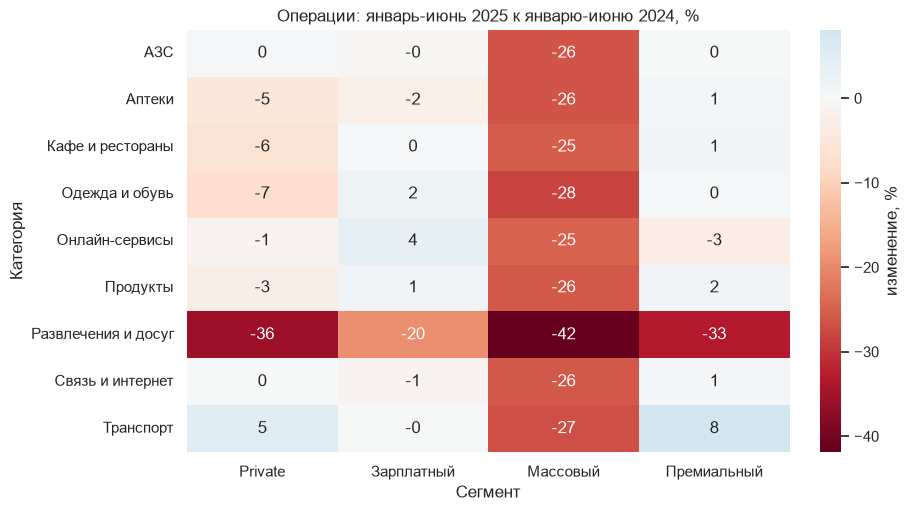

,Private,Зарплатный,Массовый,Премиальный
АЗС,0.4,-0.3,-26.3,0.2
Аптеки,-5.3,-2.5,-26.4,0.7
Кафе и рестораны,-6.1,0.5,-25.2,1.0
Одежда и обувь,-7.2,2.1,-28.1,0.4
Онлайн-сервисы,-1.2,3.8,-24.6,-3.4
Продукты,-2.7,1.3,-25.9,1.5
Развлечения и досуг,-35.8,-19.6,-41.9,-33.0
Связь и интернет,0.0,-1.1,-26.0,0.7
Транспорт,5.1,-0.1,-27.0,8.1


In [64]:
cat_seg = yoy(okx, ["category", "segment"]).unstack().round(1)

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
sns.heatmap(cat_seg, annot=True, fmt=".0f", cmap="RdBu", center=0, cbar_kws={"label": "изменение, %"}, ax=ax)
ax.set(title="Операции: январь-июнь 2025 к январю-июню 2024, %", xlabel="Сегмент", ylabel="Категория")
plt.show()
cat_seg.rename_axis(index=None, columns=None)

Что видно:

- В Массовом сегменте все категории упали примерно одинаково, от -28.1% до -24.6%, кроме "Развлечения и досуг" (-41.9%)
- В остальных сегментах категории почти на месте, от -7.2% до +8.1%, кроме "Развлечения и досуг": -35.8% в Private, -19.6% в Зарплатном и -33.0% в Премиальном

Т.е. "Развлечения и досуг" единственная категория, которая упала во всех сегментах

Клиенты без приложения падают сильнее и в Массовом сегменте, и в остальных. В 5.3 из каналов вырос только "Токен", а по описанию из задания это оплата смартфоном. Проверим, не перешли ли клиенты с приложением с пластиковой карты на смартфон: как изменились каналы у клиентов с приложением и без

In [65]:
same_months = okx[okx["half"] != "H2_2024"]
ch_app = same_months.groupby(["has_mobile_app", "channel", "half"], observed=True).size().unstack("half")
ch_app["разница"] = ch_app["H1_2025"] - ch_app["H1_2024"]
ch_app["изменение, %"] = (ch_app["H1_2025"] / ch_app["H1_2024"] - 1) * 100
(ch_app.round(1)
       .rename(index=APP_LABEL, columns={"H1_2024": "январь-июнь 2024", "H1_2025": "январь-июнь 2025"})
       .rename_axis(index=[None, None], columns=None))

январь-июнь 2024  январь-июнь 2025  разница  изменение, %
нет приложения  Карта                   40270             32095    -8175         -20.3
                Онлайн-банк             11914              8164    -3750         -31.5
                СБП                     10950              8752    -2198         -20.1
                Токен                    7329              6353     -976         -13.3
есть приложение Карта                   58694             43064   -15630         -26.6
                Онлайн-банк             16649             12537    -4112         -24.7
                СБП                     20797             18999    -1798          -8.6
                Токен                   19250             29735    10485          54.5

У клиентов с приложением "Токен" вырос на 10485 операций (+54.5%), а "Карта" упала на 15630 (-26.6%). Т.е. часть оплат картой перешла на смартфон, но не вся. В целом у клиентов с приложением операций всё равно на 9.6% меньше. Без приложения упали все каналы, от -13.3% у токена до -31.5% у онлайн-банка

Итого по разрезам (январь-июнь 2025 к январю-июню 2024, 4874 клиента):

- Падение сосредоточено в Массовом сегменте: -27.3% против -1.1% у Зарплатного, -3.7% у Премиального и -8.7% у Private
- Внутри Массового без приложения падение почти вдвое сильнее: -38.7% против -20.4% с приложением
- Старшие клиенты падают сильнее, в основном потому, что у них реже есть приложение
- Различия по городу, источнику зарплаты, типу карты и лояльности в основном объясняются составом по сегментам
- "Развлечения и досуг" единственная категория, которая упала во всех сегментах
- У клиентов с приложением часть оплат картой перешла на токен, без приложения упали все каналы

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

Метрика: число успешных операций клиента в месяц.

- Что считаем: операции со статусом "успешно", по всем четырём каналам ("Карта", "Токен", "СБП", "Онлайн-банк") и в любой валюте
- Окна: база 2024 год, делим на 12 месяцев, оценка январь-июнь 2025, делим на 6. Окна разной длины, поэтому сравниваем средний месяц
- Индекс активности = операций в месяц в оценке / операций в месяц в базе. 1 значит без изменений, меньше 1 значит операций стало меньше
- На ком: 4874 клиента, у которых базовый период виден целиком: карта открыта до 2024 года и в 2024 году не меньше 12 успешных операций 

Почему так:

- Заказчик говорит, что клиенты "стали реже пользоваться картами", это частота, а не сумма
- Число операций не зависит от валюты (курсов в данных нет, раздел 3.1) и от крупных покупок, которые сильно двигают суммы (раздел 3.4)
- Все каналы вместе, потому что все операции в выгрузке это операции по картам клиента: "Токен" та же карта в смартфоне, СБП и онлайн-банк это оплаты и переводы с карты. Переход с пластика на смартфон (раздел 5.4) не означает, что клиент стал реже пользоваться картой

База включает декабрьский пик, оценка январский провал, поэтому у клиента без изменений индекс около 0.93, а не 1. Значит снижением можно считать только индекс заметно ниже 0.93

In [66]:
def ops_count(df, start, end):
    window = (df["txn_datetime"] >= start) & (df["txn_datetime"] < end)
    return df[window].groupby("client_id").size()


m = universe.set_index("client_id")[
    ATTRS + ["age", "marketing_opt_in", "profile_conflict", "satisfaction_score", "app_last_login"]].copy()


def add_ops(prefix, df):
    m[f"{prefix}_base"] = ops_count(df, BASE_START, EVAL_START).reindex(m.index, fill_value=0)
    m[f"{prefix}_eval"] = ops_count(df, EVAL_START, DATA_END).reindex(m.index, fill_value=0)


add_ops("ops", ok_universe)
m["opm_base"] = m["ops_base"] / BASE_MONTHS
m["opm_eval"] = m["ops_eval"] / EVAL_MONTHS
m["activity_index"] = m["opm_eval"] / m["opm_base"]

print("Клиентов в расчёте активности:", len(m))
m[["ops_base", "ops_eval", "opm_base", "opm_eval", "activity_index"]].rename(columns={
    "ops_base": "операций за 2024", "ops_eval": "операций за январь-июнь 2025",
    "opm_base": "в месяц, 2024", "opm_eval": "в месяц, январь-июнь 2025", "activity_index": "индекс активности",
}).describe().round(2)

Клиентов в расчёте активности: 4874


,операций за 2024,операций за январь-июнь 2025,"в месяц, 2024","в месяц, январь-июнь 2025",индекс активности
count,4874.00,4874.00,4874.00,4874.00,4874.00
mean,82.01,32.77,6.83,5.46,0.79
std,48.28,26.38,4.02,4.40,0.37
min,12.00,0.00,1.00,0.00,0.00
25%,49.00,14.00,4.08,2.33,0.48
50%,71.00,27.00,5.92,4.50,0.80
75%,104.00,43.00,8.67,7.17,1.02
max,616.00,445.00,51.33,74.17,2.42


Медиана индекса 0.80, у четверти клиентов он ниже 0.48, а минимум 0, т.е. есть клиенты без единой операции в январе-июне 2025 года. Посмотрим на распределение индекса. В 5.4 падение сосредоточено в Массовом сегменте, поэтому покажем его отдельно от остальных

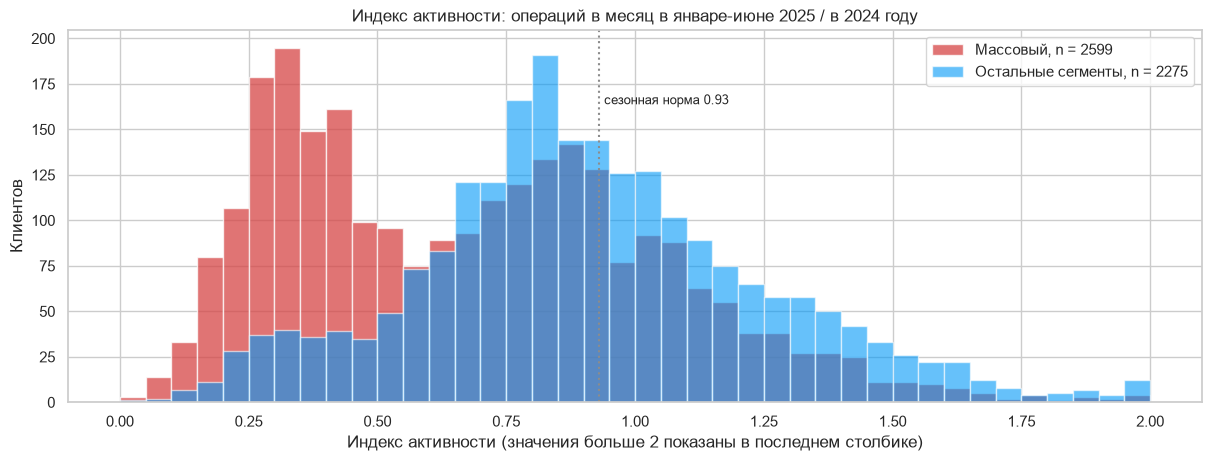

In [67]:
is_mass = m["segment"] == "Массовый"

fig, ax = plt.subplots(figsize=(12, 4.5), layout="constrained")
bins = np.arange(0, 2.05, 0.05)
ax.hist(m.loc[is_mass, "activity_index"].clip(upper=2), bins=bins, alpha=0.75, color="#D64545",
        label=f"Массовый, n = {is_mass.sum()}")
ax.hist(m.loc[~is_mass, "activity_index"].clip(upper=2), bins=bins, alpha=0.6, color="#0098F8",
        label=f"Остальные сегменты, n = {(~is_mass).sum()}")
ax.axvline(SEASONAL_NORM, color="#8C8C8C", ls=":")
ax.text(SEASONAL_NORM + 0.01, ax.get_ylim()[1] * 0.8, f"сезонная норма {SEASONAL_NORM:.2f}", fontsize=9)
ax.set(title="Индекс активности: операций в месяц в январе-июне 2025 / в 2024 году",
       xlabel="Индекс активности (значения больше 2 показаны в последнем столбике)", ylabel="Клиентов")
ax.legend()
plt.show()

Что видно: 

У остальных сегментов один горб около 0.8-0.9, рядом с сезонной нормой. У Массового сегмента два горба: один около 0.3, второй около 0.8-0.9, как у остальных, а между ними провал. Т.е. часть клиентов Массового сегмента ведёт себя как остальные сегменты, а у части операций стало примерно втрое меньше. Посчитаем клиентов Массового сегмента по интервалам индекса, чтобы найти, где провал

In [68]:
hist_mass = pd.cut(m.loc[is_mass, "activity_index"], np.arange(0, 1.3, 0.1)).value_counts().sort_index()
print("Массовый сегмент, клиентов в каждом интервале индекса:")
hist_mass.to_frame("клиентов").T.rename_axis(columns=None)

Массовый сегмент, клиентов в каждом интервале индекса:


,"(0.0, 0.1]","(0.1, 0.2]","(0.2, 0.3]","(0.3, 0.4]","(0.4, 0.5]","(0.5, 0.6]","(0.6, 0.7]","(0.7, 0.8]","(0.8, 0.9]","(0.9, 1.0]","(1.0, 1.1]","(1.1, 1.2]"
клиентов,15,120,279,359,269,147,187,233,269,240,146,118


Провал на 0.5-0.6: там 147 клиентов, а по бокам 269 (0.4-0.5) и 187 (0.6-0.7). Поэтому угасанием считаем индекс меньше 0.5, т.е. "активность упала больше чем вдвое": граница проходит по провалу и отделяет левый горб от правого

Проверим, не шум ли это. В 2024 году общего падения не было, поэтому сравним второе полугодие 2024 года с первым у тех же клиентов: так видно, какое падение даёт обычный разброс. В отношении полугодий есть ещё сезонный рост к декабрю, поэтому делим его на медиану по всем клиентам и умножаем на сезонную норму 0.93. Получается индекс клиента, у которого ничего не изменилось

In [69]:
h1 = ops_count(ok_universe, BASE_START, H1_2024_END).reindex(m.index, fill_value=0) / 6
h2 = ops_count(ok_universe, H1_2024_END, EVAL_START).reindex(m.index, fill_value=0) / 6
h2_to_h1 = (h2 / h1).replace(np.inf, np.nan)
print(f"Медиана отношения второго полугодия 2024 года к первому: {h2_to_h1.median():.2f}")

m["noise_index"] = h2_to_h1 / h2_to_h1.median() * SEASONAL_NORM
q1, q3 = m["noise_index"].quantile([0.25, 0.75])
print(f"Индекс клиента без изменений: медиана {m['noise_index'].median():.2f}, квартили {q1:.2f} и {q3:.2f}")

FADE_THRESHOLD = 0.5
MODERATE_UPPER = round(q1, 1)

def bands(s):
    n = s.notna().sum()
    return pd.Series({
        f"меньше {FADE_THRESHOLD}": share((s < FADE_THRESHOLD).sum(), n),
        f"от {FADE_THRESHOLD} до {MODERATE_UPPER}": share(s.between(FADE_THRESHOLD, MODERATE_UPPER, inclusive="left").sum(), n),
    })


pd.DataFrame({
    "без изменений: второе полугодие 2024 к первому × сезонная норма": bands(m["noise_index"]),
    "индекс активности: январь-июнь 2025 к 2024": bands(m["activity_index"]),
})

Медиана отношения второго полугодия 2024 года к первому: 1.15
Индекс клиента без изменений: медиана 0.93, квартили 0.79 и 1.09


,без изменений: второе полугодие 2024 к первому × сезонная норма,индекс активности: январь-июнь 2025 к 2024
меньше 0.5,80 из 4874 (1.6%),1256 из 4874 (25.8%)
от 0.5 до 0.8,1165 из 4874 (23.9%),1197 из 4874 (24.6%)


Медиана отношения полугодий 1.15, это та же сезонность, что в 5.3: второе полугодие с декабрьским пиком выше первого. У клиента без изменений индекс в среднем 0.93, но у четверти таких клиентов он из-за обычного разброса ниже 0.79. Округляем эту границу до 0.8: снижение до 0.8 по одному клиенту не отличить от разброса, а индекс 0.8 и выше считаем "активность не упала".

Что видно в таблице:

- Ниже 0.5 из-за разброса оказалось бы только 80 из 4874 клиентов (1.6%), а фактически их 1256 (25.8%), т.е. угасание это настоящее падение, а не шум
- От 0.5 до 0.8 из-за разброса и сезонности ожидалось бы 1165 клиентов, фактически их 1197, т.е. почти всё такое снижение объясняется разбросом

Оценка грубая: в 2024 году оба окна по полгода, поэтому разброс в ней даже немного больше, чем у индекса, где база целый год

В 5.3 у онлайн-банка в марте-апреле 2025 года провал сразу у всех сегментов, он снижает индекс у всех клиентов. Проверим, насколько это меняет число угасающих: посчитаем индекс без онлайн-банка

In [70]:
no_online = ok_universe[ok_universe["channel"] != "Онлайн-банк"]
m["index_no_online"] = ((ops_count(no_online, EVAL_START, DATA_END).reindex(m.index, fill_value=0) / EVAL_MONTHS)
                        / (ops_count(no_online, BASE_START, EVAL_START).reindex(m.index, fill_value=0) / BASE_MONTHS))
print(f"Индекс ниже {FADE_THRESHOLD} по всем каналам:", share((m["activity_index"] < FADE_THRESHOLD).sum(), len(m)))
print(f"Индекс ниже {FADE_THRESHOLD} без онлайн-банка:", share((m["index_no_online"] < FADE_THRESHOLD).sum(), len(m)))

Индекс ниже 0.5 по всем каналам: 1256 из 4874 (25.8%)
Индекс ниже 0.5 без онлайн-банка: 1208 из 4874 (24.8%)


Без онлайн-банка ниже 0.5 1208 из 4874 клиентов (24.8%) против 1256 (25.8%) по всем каналам. Т.е. провал онлайн-банка почти не меняет число угасающих, поэтому оставляем все каналы

Метрика считает только число операций, а в 5.3 медиана суммы операции снизилась у всех сегментов. Проверим, видно ли это у клиентов, у которых частота не упала, т.е. индекс 0.8 и выше

In [71]:
stable_ids = m.index[m["activity_index"] >= MODERATE_UPPER]
rub_stable = ok_universe[(ok_universe["currency"] == "RUB") & ok_universe["client_id"].isin(stable_ids)]
ticket_before = rub_stable.loc[rub_stable["txn_datetime"] < H1_2024_END, "amount"].median()
ticket_after = rub_stable.loc[rub_stable["txn_datetime"] >= EVAL_START, "amount"].median()
print(f"Клиентов, у которых частота не упала (индекс {MODERATE_UPPER} и выше):", share(len(stable_ids), len(m)))
print(f"У них медиана суммы операции: январь-июнь 2024 {ticket_before:.0f} руб., январь-июнь 2025 {ticket_after:.0f} руб. "
      f"({ticket_after / ticket_before - 1:+.1%})")

Клиентов, у которых частота не упала (индекс 0.8 и выше): 2421 из 4874 (49.7%)
У них медиана суммы операции: январь-июнь 2024 1151 руб., январь-июнь 2025 1036 руб. (-10.0%)


У 2421 из 4874 клиентов частота не упала, а медиана суммы операции у них снизилась на 10.0%, с 1151 до 1036 руб. за январь-июнь 2025 к январю-июню 2024.

Чего метрика не увидит:

1. Снижение суммы при той же частоте, как у этих 2421 клиента
2. Ушедших клиентов: 342 клиента ушли из банка и не входят в справочник действующих
3. Клиентов с новой картой: у 779 клиентов карта открыта в 2024-2025 годах, а операции по прежней карте в данные не попали
4. Перенос крупных покупок в другой банк, если клиент продолжает платить нашей картой за мелочи: частота сохраняется, а доля кошелька падает
5. Форму падения внутри полугодия: индекс одинаковый у клиента, который упал в январе, и у того, кто угасал постепенно

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

Угасание это индекс меньше 0.5. Посмотрим, сколько угасающих в каждом сегменте с приложением и без

In [72]:
m["fade"] = m["activity_index"] < FADE_THRESHOLD
fade_by = m.groupby(["segment", "has_mobile_app"], observed=True)["fade"].agg(клиентов="size", угасающих="sum")
fade_by["доля угасающих, %"] = (fade_by["угасающих"] / fade_by["клиентов"] * 100).round(1)
print("Угасающих всего:", share(m["fade"].sum(), len(m)))
print("По сегментам:", ", ".join(f"{seg} {n}" for seg, n in m.groupby("segment", observed=True)["fade"].sum().items()))
fade_by.rename(index=APP_LABEL).rename_axis(index=[None, None])

Угасающих всего: 1256 из 4874 (25.8%)
По сегментам: Private 19, Зарплатный 128, Массовый 1020, Премиальный 89


клиентов  угасающих  доля угасающих, %
Private     нет приложения         84          9               10.7
            есть приложение       107         10                9.3
Зарплатный  нет приложения        515         79               15.3
            есть приложение       769         49                6.4
Массовый    нет приложения       1042        548               52.6
            есть приложение      1557        472               30.3
Премиальный нет приложения        309         44               14.2
            есть приложение       491         45                9.2

Что видно:

- Угасающих 1256, из них 1020 в Массовом сегменте
- В Массовом без приложения угасают 548 из 1042 клиентов (52.6%), с приложением 472 из 1557 (30.3%). Это две большие группы с разной долей угасания, поэтому делим Массовый сегмент по приложению
- В остальных сегментах угасает от 6.4% до 15.3% клиентов: 128 в Зарплатном, 89 в Премиальном и 19 в Private. Каждый по отдельности меньше 150, поэтому объединяем их в одну группу

По угасанию получаются три группы: Массовый без приложения, Массовый с приложением и остальные сегменты

Развлечения. В разделе 5.4 "Развлечения и досуг" единственная категория, которая упала во всех сегментах. Посмотрим на клиентов, которые платили за развлечения регулярно, т.е. в среднем хотя бы раз в месяц в 2024 году: развлечения у них снизились понемногу у всех или у части клиентов почти исчезли?

In [73]:
ENT = "Развлечения и досуг"
add_ops("ent", ok_universe[ok_universe["category"] == ENT])
m["ent_index"] = (m["ent_eval"] / EVAL_MONTHS) / (m["ent_base"] / BASE_MONTHS)

ENT_MIN_BASE_OPS = 12       # развлечения — регулярная категория: в среднем раз в месяц в 2024 году
regular_ent = m.loc[m["ent_base"] >= ENT_MIN_BASE_OPS, "ent_index"]
print("Клиентов, регулярно плативших за развлечения в 2024 году:", len(regular_ent))
bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.2, np.inf]
labels = [f"{a}-{b}" for a, b in zip(bins[:-2], bins[1:-1])] + [f"больше {bins[-2]}"]
pd.cut(regular_ent, bins, labels=labels, include_lowest=True).value_counts().sort_index().to_frame("клиентов").T.rename_axis(columns=None)

Клиентов, регулярно плативших за развлечения в 2024 году: 913


,0-0.1,0.1-0.2,0.2-0.3,0.3-0.4,0.4-0.5,0.5-0.6,0.6-0.7,0.7-0.8,0.8-0.9,0.9-1.0,1.0-1.2,больше 1.2
клиентов,223,161,58,53,51,33,42,56,39,45,63,89


Почти исчезли у части: у 223 из 913 клиентов развлечений стало меньше 0.1 от прежнего и ещё у 161 от 0.1 до 0.2, а дальше в каждом интервале до 1.0 от 33 до 58 клиентов. Т.е. это отдельная группа, а не край общего распределения. Пик заканчивается на 0.2, а интервал 0.2-0.3 уже на уровне остальных, поэтому границу проводим посередине, по 0.25: "развлечений стало меньше четверти от прежнего"

Правила групп. У каждой две части: кто это (признак клиента или его трат) и что произошло (характер падения).

| группа | кто | что произошло |
|---|---|---|
| G1 | Массовый сегмент, нет мобильного приложения | угасание: в январе-июне 2025 года операций в месяц меньше половины от 2024 года |
| G2 | Массовый сегмент, есть приложение | то же угасание |
| G3 | Зарплатный, Премиальный и Private сегменты | то же угасание |
| G4 | регулярно платили за развлечения: в 2024 году не меньше 12 операций в "Развлечениях и досуге" | развлечений стало меньше четверти от прежнего |

Все поля в правилах считаются из двух выданных таблиц, поэтому правило применимо к клиенту из новой выгрузки, если у него виден базовый год. Карта открыта до его начала и в нём не меньше 12 успешных операций. Порог 0.5 только уточняет "угасание", а само правило говорит, кто эти люди.

Конфликты: клиент попадает в первую подходящую группу по порядку от G1 до G4. Угасание всей активности важнее потери одной категории. Если клиент бросил вообще все траты, говорить с ним только о развлечениях бессмысленно.


In [74]:
ENT_LOST_THRESHOLD = 0.25

m["ent_lost"] = (m["ent_base"] >= ENT_MIN_BASE_OPS) & (m["ent_index"] < ENT_LOST_THRESHOLD)

GROUP_RULES = {
    "G1_массовый_без_приложения": is_mass & ~m["has_mobile_app"] & m["fade"],
    "G2_массовый_с_приложением": is_mass & m["has_mobile_app"] & m["fade"],
    "G3_зарплатный_премиальный_private": ~is_mass & m["fade"],
    "G4_ушли_из_развлечений": m["ent_lost"],
}
rules = pd.DataFrame(GROUP_RULES)
m["n_rules"] = rules.sum(axis=1)
m["group"] = np.select(list(GROUP_RULES.values()), list(GROUP_RULES), default=None)

print("Клиентов, подходящих хотя бы под одно правило:", rules.any(axis=1).sum())
print("Подходят сразу под два правила:", (m["n_rules"] == 2).sum(), "| под три и больше:", (m["n_rules"] > 2).sum())
pd.DataFrame({"подходят под правило": rules.sum(), "назначено по приоритету": m["group"].value_counts()})

Клиентов, подходящих хотя бы под одно правило: 1589
Подходят сразу под два правила: 69 | под три и больше: 0


,подходят под правило,назначено по приоритету
G1_массовый_без_приложения,548,548
G2_массовый_с_приложением,472,472
G3_зарплатный_премиальный_private,236,236
G4_ушли_из_развлечений,402,333


Посмотрим пересечения, кто из угасающих клиентов ещё и бросил развлечения

In [75]:
overlap = m[m["n_rules"] > 1]
overlap.groupby("group").size().to_frame("клиентов, подходят и под G4").rename_axis(index=None)

,"клиентов, подходят и под G4"
G1_массовый_без_приложения,12
G2_массовый_с_приложением,16
G3_зарплатный_премиальный_private,41


69 угасающих клиентов к тому же бросили развлечения: 12 в G1, 16 в G2 и 41 в G3. По приоритету они остаются в угасающих группах, т.е. в G4 только клиенты, у которых упали именно развлечения

Отбор в кампанию: есть согласие на маркетинговую коммуникацию и профиль без двух версий.

In [76]:
candidates = m[m["group"].notna()]
by_group = candidates.groupby("group")
selection = pd.DataFrame({
    "подходят": by_group.size(),
    "нет согласия": by_group["marketing_opt_in"].apply(lambda s: (~s).sum()),
    "две версии профиля": by_group["profile_conflict"].sum(),
})
eligible = candidates["marketing_opt_in"] & ~candidates["profile_conflict"]
campaign = candidates[eligible].copy()
selection["в кампании"] = campaign.groupby("group").size()
selection.loc["итого"] = selection.sum()
selection.rename_axis(index=None)

,подходят,нет согласия,две версии профиля,в кампании
G1_массовый_без_приложения,548,70,1,478
G2_массовый_с_приложением,472,48,1,423
G3_зарплатный_премиальный_private,236,26,0,210
G4_ушли_из_развлечений,333,42,1,290
итого,1589,186,3,1401


Без согласия 186 клиентов, с двумя версиями профиля 3, в кампанию проходят 1401 из 1589

In [77]:
sizes = campaign["group"].value_counts()
assert 3 <= len(sizes) <= 5, "групп должно быть от 3 до 5"
assert (sizes >= 150).all(), "группа меньше 150 человек"
assert len(campaign) <= 2000, "больше 2000 клиентов"
assert campaign.index.is_unique, "клиент в двух группах"
print("Клиентов в кампании:", len(campaign), "из лимита 2000 | групп:", len(sizes),
      "| в самой маленькой группе:", sizes.min())

Клиентов в кампании: 1401 из лимита 2000 | групп: 4 | в самой маленькой группе: 210


Посмотрим на портрет каждой группы в кампании и для сравнения на клиентов, которые не подходят ни под одно правило

In [78]:
add_ops("other", ok_universe[ok_universe["category"] != ENT])
m["other_index"] = (m["other_eval"] / EVAL_MONTHS) / (m["other_base"] / BASE_MONTHS)
m["index_q1_2025"] = ops_count(ok_universe, EVAL_START, pd.Timestamp("2025-04-01")).reindex(m.index, fill_value=0) / 3 / m["opm_base"]
m["index_q2_2025"] = ops_count(ok_universe, pd.Timestamp("2025-04-01"), DATA_END).reindex(m.index, fill_value=0) / 3 / m["opm_base"]

m["group_or_rest"] = m["group"].fillna("нет падения по правилам")
m["ops_may_jun"] = ops_count(ok_universe, pd.Timestamp("2025-05-01"), DATA_END).reindex(m.index, fill_value=0)
shown = m.index.isin(campaign.index) | m["group"].isna()

def pct(mask):
    return mask.mean() * 100

profile = m[shown].groupby("group_or_rest").agg(**{
    "клиентов": ("activity_index", "size"),
    "медиана индекса": ("activity_index", "median"),
    "индекс январь-март": ("index_q1_2025", "median"),
    "индекс апрель-июнь": ("index_q2_2025", "median"),
    "индекс развлечений": ("ent_index", "median"),
    "индекс прочих категорий": ("other_index", "median"),
    "без операций в мае-июне, %": ("ops_may_jun", lambda s: pct(s == 0)),
    "бросили развлечения, %": ("ent_lost", pct),
    "с приложением, %": ("has_mobile_app", pct),
    "60 лет и старше, %": ("age", lambda s: pct(s >= 60)),
    "медиана возраста": ("age", "median"),
})
print("Угасающих без единой операции в мае-июне 2025:", share((m["fade"] & (m["ops_may_jun"] == 0)).sum(), m["fade"].sum()))
display(profile.round({c: 1 if c.endswith("%") else 2 for c in profile.columns}).rename_axis(index=None))

g3 = m.loc[campaign.index[campaign["group"] == "G3_зарплатный_премиальный_private"]]
print("G3 в кампании по сегментам:")
g3.groupby("segment", observed=True).agg(**{
    "в кампании": ("activity_index", "size"),
    "медиана индекса": ("activity_index", "median"),
    "индекс январь-март": ("index_q1_2025", "median"),
    "индекс апрель-июнь": ("index_q2_2025", "median"),
}).round(2).rename_axis(index=None)

Угасающих без единой операции в мае-июне 2025: 202 из 1256 (16.1%)


,клиентов,медиана индекса,индекс январь-март,индекс апрель-июнь,индекс развлечений,индекс прочих категорий,"без операций в мае-июне, %","бросили развлечения, %","с приложением, %","60 лет и старше, %",медиана возраста
G1_массовый_без_приложения,478,0.31,0.36,0.22,0.00,0.31,21.8,2.3,0.0,44.4,57.0
G2_массовый_с_приложением,423,0.33,0.36,0.28,0.00,0.34,11.8,3.8,100.0,23.2,50.0
G3_зарплатный_премиальный_private,210,0.33,0.39,0.26,0.21,0.33,13.8,16.2,44.3,37.1,54.0
G4_ушли_из_развлечений,290,0.72,0.65,0.77,0.10,0.91,0.0,100.0,52.4,31.0,52.0
нет падения по правилам,3285,0.92,0.88,0.98,0.90,0.93,0.2,0.0,65.9,27.6,50.0


G3 в кампании по сегментам:


,в кампании,медиана индекса,индекс январь-март,индекс апрель-июнь
Private,18,0.39,0.42,0.25
Зарплатный,113,0.32,0.39,0.25
Премиальный,79,0.36,0.38,0.27


Что видно:

- У G1-G3 медиана индекса 0.31-0.33, и падение продолжается внутри полугодия: в январе-марте 0.36-0.39, в апреле-июне 0.22-0.28. Остальные категории падают вместе с развлечениями: индекс прочих категорий 0.31-0.34
- Без единой операции в мае-июне 21.8% клиентов G1, 11.8% G2 и 13.8% G3, а всего 202 из 1256 угасающих (16.1%). У ушедших клиентов из 2.4 операции тоже сначала прекращались, т.е. эти клиенты могут быть на грани ухода
- У G4 упали только развлечения: индекс развлечений 0.10, прочих категорий 0.91, в целом 0.72
- G1 старше остальных: медиана возраста 57 лет, 60 лет и старше 44.4% против 27.6% у клиентов без падения по правилам
- Внутри G3 сегменты падают одинаково: медиана индекса 0.32 у Зарплатного, 0.36 у Премиального и 0.39 у Private, в апреле-июне от 0.25 до 0.27

За счёт чего упала активность. Посмотрим на изменение числа операций в месяц по категориям и по каналам внутри каждой группы

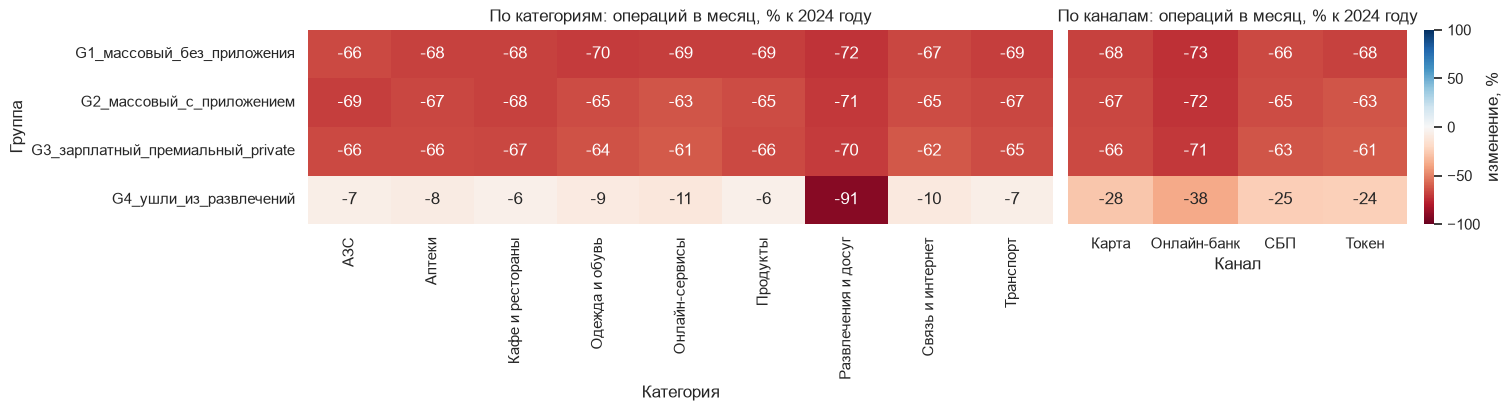

,АЗС,Аптеки,Кафе и рестораны,Одежда и обувь,Онлайн-сервисы,Продукты,Развлечения и досуг,Связь и интернет,Транспорт
G1_массовый_без_приложения,-66.0,-68.0,-68.0,-70.0,-69.0,-69.0,-72.0,-67.0,-69.0
G2_массовый_с_приложением,-69.0,-67.0,-68.0,-65.0,-63.0,-65.0,-71.0,-65.0,-67.0
G3_зарплатный_премиальный_private,-66.0,-66.0,-67.0,-64.0,-61.0,-66.0,-70.0,-62.0,-65.0
G4_ушли_из_развлечений,-7.0,-8.0,-6.0,-9.0,-11.0,-6.0,-91.0,-10.0,-7.0


,Карта,Онлайн-банк,СБП,Токен
G1_массовый_без_приложения,-68.0,-73.0,-66.0,-68.0
G2_массовый_с_приложением,-67.0,-72.0,-65.0,-63.0
G3_зарплатный_премиальный_private,-66.0,-71.0,-63.0,-61.0
G4_ушли_из_развлечений,-28.0,-38.0,-25.0,-24.0


In [79]:
okg = ok_universe[ok_universe["client_id"].isin(campaign.index)].join(campaign["group"], on="client_id")

def change_by(df, by):
    per_month = df.groupby(["group", by, "period"], observed=True).size().unstack("period")
    return ((per_month["eval"] / EVAL_MONTHS) / (per_month["base"] / BASE_MONTHS) - 1).unstack(by)

by_cat = (change_by(okg, "category") * 100).round(0)
by_chan = (change_by(okg, "channel") * 100).round(0)

fig, axes = plt.subplots(1, 2, figsize=(15, 4), layout="constrained", width_ratios=[2.2, 1])
sns.heatmap(by_cat, annot=True, fmt=".0f", cmap="RdBu", center=0, vmin=-100, vmax=100, cbar=False, ax=axes[0])
axes[0].set(title="По категориям: операций в месяц, % к 2024 году", xlabel="Категория", ylabel="Группа")
sns.heatmap(by_chan, annot=True, fmt=".0f", cmap="RdBu", center=0, vmin=-100, vmax=100,
            cbar_kws={"label": "изменение, %"}, ax=axes[1])
axes[1].set(title="По каналам: операций в месяц, % к 2024 году", xlabel="Канал", ylabel="")
axes[1].set_yticklabels([])
plt.show()
display(by_cat.rename_axis(index=None, columns=None))
by_chan.rename_axis(index=None, columns=None)

Что видно:

У G1-G3 все категории упали одинаково, от -72% до -61%, и все каналы тоже, от -73% до -61%. У G2 токен упал на 63%, т.е. это не переход на оплату смартфоном, как у части клиентов с приложением в 5.4. У G4 развлечения -91%, а остальные категории от -11% до -6%, т.е. около сезонной нормы 0.93

Как падала активность по месяцам. Число операций клиента в месяц, делённое на его средний месяц 2024 года, в среднем по группе

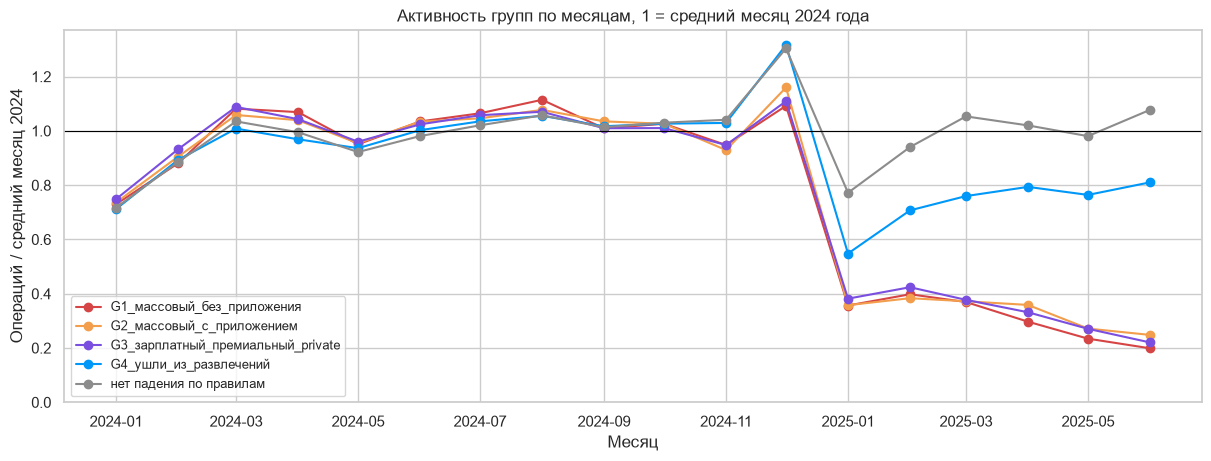

,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01,2024-10-01,2024-11-01,2024-12-01,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01
G1_массовый_без_приложения,0.73,0.88,1.08,1.07,0.95,1.03,1.06,1.11,1.01,1.03,0.95,1.09,0.36,0.40,0.37,0.30,0.23,0.20
G2_массовый_с_приложением,0.74,0.90,1.06,1.04,0.95,1.03,1.05,1.08,1.03,1.03,0.93,1.16,0.36,0.38,0.37,0.36,0.27,0.25
G3_зарплатный_премиальный_private,0.75,0.93,1.09,1.04,0.96,1.02,1.06,1.07,1.01,1.01,0.95,1.11,0.38,0.42,0.38,0.33,0.27,0.22
G4_ушли_из_развлечений,0.71,0.89,1.01,0.97,0.94,1.00,1.03,1.06,1.02,1.03,1.03,1.32,0.55,0.71,0.76,0.79,0.76,0.81
нет падения по правилам,0.72,0.89,1.03,0.99,0.92,0.98,1.02,1.06,1.01,1.03,1.04,1.30,0.77,0.94,1.05,1.02,0.98,1.08


In [80]:
client_month = (ok_universe.groupby(["client_id", "month"]).size()
                .unstack(fill_value=0).reindex(m.index, fill_value=0))
relative = client_month.div(m["opm_base"], axis=0)
trajectory = relative[shown].groupby(m.loc[shown, "group_or_rest"]).mean().T

fig, ax = plt.subplots(figsize=(12, 4.5), layout="constrained")
colors = ["#D64545", "#F29E4C", "#7A4FE0", "#0098F8", "#8C8C8C"]
for (name, series), color in zip(trajectory.items(), colors):
    ax.plot(series.index, series.values, marker="o", label=name, color=color)
ax.axhline(1, color="black", lw=0.8)
ax.set(title="Активность групп по месяцам, 1 = средний месяц 2024 года", xlabel="Месяц",
       ylabel="Операций / средний месяц 2024")
ax.set_ylim(0, None)
ax.legend(fontsize=9)
plt.show()
trajectory.T.round(2).rename_axis(index=None, columns=None)

Что видно: 

В начале 2024 года все группы идут одинаково, а в ноябре-декабре 2024 года у G1-G3 операций уже меньше, чем у клиентов без падения по правилам: в ноябре 0.93-0.95 против 1.04, в декабрьский пик 1.09-1.16 против 1.30. Основной обрыв в январе 2025 года, до 0.36-0.38, и дальше активность продолжает снижаться, к июню до 0.20-0.25. G4 в январе 0.55, а потом возвращается к 0.76-0.81

Развлечения по месяцам у всех, кто регулярно платил за них в 2024 году: операций в месяц относительно своего среднего месяца 2024 года

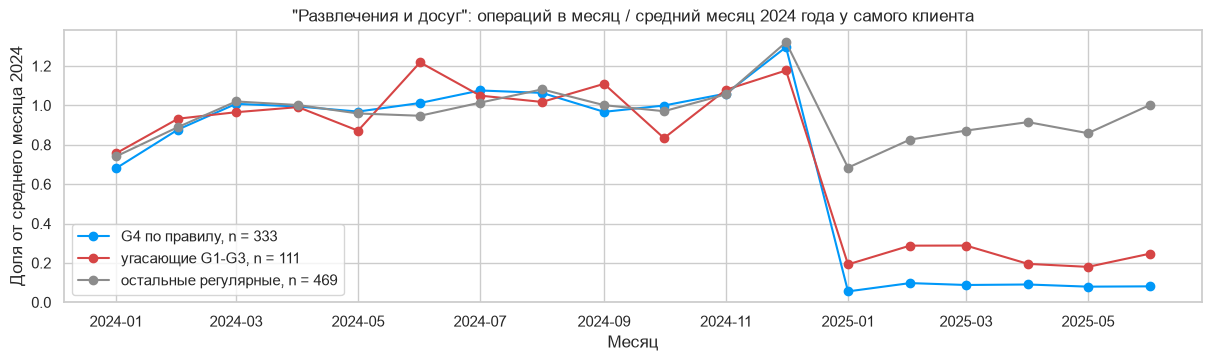

,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01,2024-10-01,2024-11-01,2024-12-01,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01
G4 по правилу,0.68,0.88,1.01,0.99,0.97,1.01,1.08,1.06,0.97,1.00,1.06,1.30,0.06,0.10,0.09,0.09,0.08,0.08
остальные регулярные,0.74,0.89,1.02,1.00,0.96,0.95,1.01,1.08,1.00,0.97,1.06,1.32,0.68,0.83,0.87,0.91,0.86,1.00
угасающие G1-G3,0.76,0.93,0.97,0.99,0.87,1.22,1.05,1.02,1.11,0.83,1.08,1.18,0.19,0.29,0.29,0.19,0.18,0.25


In [81]:
regular = m[m["ent_base"] >= ENT_MIN_BASE_OPS]
ent_month = (ok_universe[ok_universe["category"] == ENT].groupby(["client_id", "month"]).size()
             .unstack(fill_value=0).reindex(regular.index, fill_value=0))
ent_relative = ent_month.div(regular["ent_base"] / BASE_MONTHS, axis=0)
who = pd.Series(np.select([regular["group"] == "G4_ушли_из_развлечений", regular["fade"]],
                          ["G4 по правилу", "угасающие G1-G3"], "остальные регулярные"), index=regular.index)
ent_profile = ent_relative.groupby(who).mean().T

fig, ax = plt.subplots(figsize=(12, 3.5), layout="constrained")
for name, color in [("G4 по правилу", "#0098F8"), ("угасающие G1-G3", "#D64545"), ("остальные регулярные", "#8C8C8C")]:
    ax.plot(ent_profile.index, ent_profile[name], marker="o", color=color, label=f"{name}, n = {(who == name).sum()}")
ax.set(title="\"Развлечения и досуг\": операций в месяц / средний месяц 2024 года у самого клиента",
       xlabel="Месяц", ylabel="Доля от среднего месяца 2024")
ax.set_ylim(0, None)
ax.legend()
plt.show()
ent_profile.T.round(2).rename_axis(columns=None)

Что видно:

 У G4 развлечения обрываются ровно на границе года: 1.30 в декабре 2024 года и 0.06 в январе 2025, дальше 0.08-0.10. У угасающих G1-G3 развлечения падают вместе со всей активностью, а у остальных регулярных клиентов в январе 0.68 и к июню 1.00, т.е. обычная сезонность

Посмотрим, как меняются группы в кампании при другом пороге угасания, без онлайн-банка и при другой границе для развлечений. И сколько угасающих остаются ниже 0.5, если сравнивать с январём-июнем 2024 года, а не со всем 2024 годом

In [82]:
ok_c = m["marketing_opt_in"] & ~m["profile_conflict"]

def fade_groups(fade):
    return pd.Series({"G1": (is_mass & ~m["has_mobile_app"] & fade & ok_c).sum(),
                      "G2": (is_mass & m["has_mobile_app"] & fade & ok_c).sum(),
                      "G3": (~is_mass & fade & ok_c).sum()})

sens = {f"порог {thr}": fade_groups(m["activity_index"] < thr) for thr in [0.4, 0.5, 0.6]}
sens["порог 0.5 без онлайн-банка"] = fade_groups(m["index_no_online"] < FADE_THRESHOLD)   # индекс из раздела 6
display(pd.DataFrame(sens))

regular_ok = (m["ent_base"] >= ENT_MIN_BASE_OPS) & ~m["fade"] & ok_c
print("G4 в кампании при границе 0.2, 0.25 и 0.3:",
      ", ".join(str((regular_ok & (m["ent_index"] < thr)).sum()) for thr in [0.2, 0.25, 0.3]))

m["index_yoy"] = m["opm_eval"] / (ops_count(ok_universe, BASE_START, H1_2024_END).reindex(m.index, fill_value=0) / 6)
print("Угасающих, которые остаются ниже 0.5 и против января-июня 2024:",
      share((m["fade"] & (m["index_yoy"] < FADE_THRESHOLD)).sum(), m["fade"].sum()))

,порог 0.4,порог 0.5,порог 0.6,порог 0.5 без онлайн-банка
G1,373,478,535,459
G2,302,423,505,409
G3,143,210,309,204


G4 в кампании при границе 0.2, 0.25 и 0.3: 277, 290, 321
Угасающих, которые остаются ниже 0.5 и против января-июня 2024: 1129 из 1256 (89.9%)


Что видно:

- При пороге 0.4 группы меньше, и G3 только 143, ниже минимума в 150. При пороге 0.6 больше: G1 535, G2 505, G3 309. Порог 0.5 выбран по провалу в распределении (раздел 6), а не под размер групп
- Без онлайн-банка G1 459, G2 409 и G3 204 вместо 478, 423 и 210, т.е. группы почти не меняются
- G4 при границе 0.2 и 0.3 это 277 и 321 клиент вместо 290, т.е. группа есть при любой из этих границ
- При сравнении с январём-июнем 2024 года ниже 0.5 остаются 1129 из 1256 угасающих (89.9%), т.е. угасание не следствие сезонности

Группы для кампании: 1401 клиент из лимита 2000.

| группа | в кампании | кто | что произошло и за счёт чего |
|---|---|---|---|
| G1 | 478 | Массовый, без приложения, медиана возраста 57 лет | с января 2025 года около трети прежней активности, к июню 0.20 от среднего месяца 2024 года, у 21.8% нет ни одной операции в мае-июне. Падение одинаковое во всех категориях (от -72% до -66%) и во всех каналах (от -73% до -66%) |
| G2 | 423 | Массовый, с приложением, медиана возраста 50 лет | тот же рисунок: 0.36 в январе, 0.25 в июне. Все категории от -71% до -63%, токен тоже упал (-63%), т.е. это не переход на оплату смартфоном |
| G3 | 210 | Зарплатный (113), Премиальный (79), Private (18) | 0.38 в январе, 0.22 в июне, все категории от -70% до -61% |
| G4 | 290 | регулярно платили за развлечения | развлечения -91%, остальные категории от -11% до -6%, т.е. около сезонной нормы. Активность в целом 0.72 от 2024 года |

Что это значит. Это гипотезы, а не доказанные причины: данные показывают, как упала активность, но не почему.

- В G1-G3 падение одинаковое по всем категориям и каналам, начинается в ноябре-декабре 2024 года и обрывается в январе 2025. Так выглядит событие, которое затронуло клиента целиком: смена условий обслуживания или перенос основной карты в другой банк. Если бы клиенты отказывались от отдельных покупок, упали бы отдельные категории. Проверить можно опросом части группы или данными о тарифах, которых в выгрузке нет
- В G4 обрыв ровно 1 января и только в одной категории похож на окончание акции, кешбэка или партнёрской программы в развлечениях. Это нужно уточнить у продуктовой команды

Почему G3 объединяет три сегмента. По отдельности ни один не набирает 150 человек (113, 79 и 18), а падают они одинаково (таблица по сегментам G3 выше). Сами эти сегменты в целом почти не падают (от -8.7% до -1.1% год к году, раздел 5.4), т.е. G3 это отдельные клиенты, а не тренд сегмента

### 7.1. Кого в кампанию не берём и почему

Посмотрим, почему остальные клиенты справочника не попали в кампанию. У каждого клиента одна причина, первая подходящая по порядку списка, поэтому причины не пересекаются и в сумме дают весь справочник.

Отдельно выделим клиентов, которые перешли с пластиковой карты на токен: у клиентов с приложением часть оплат картой перешла на смартфон, и по одной "Карте" такие клиенты выглядели бы угасающими. Переходом считаем, если операций "Картой" в месяц стало меньше половины от 2024 года, а доля токена во всех операциях выросла хотя бы на 20 процентных пунктов. От этих порогов зависит только, с какой причиной клиент попадает в список: под правила групп такие клиенты не подходят в любом случае

In [83]:
add_ops("card", ok_universe[ok_universe["channel"] == "Карта"])
add_ops("token", ok_universe[ok_universe["channel"] == "Токен"])

rest = m[m["group"].isna()]
switchers = rest[(rest["card_eval"] / EVAL_MONTHS < 0.5 * rest["card_base"] / BASE_MONTHS)
                 & ((rest["token_eval"] / rest["ops_eval"]) - (rest["token_base"] / rest["ops_base"]) >= 0.2)]
m["token_switch"] = m.index.isin(switchers.index)

directory = clients.set_index("client_id")
in_group = m["group"].notna().reindex(directory.index, fill_value=False)
idx = m["activity_index"].reindex(directory.index)
REASONS = {
    "в кампании": directory.index.isin(campaign.index),
    "карта открыта в 2024–2025: база 2024 года не видна": directory["card_open_date"] >= BASE_START,
    f"меньше {MIN_BASE_OPS} успешных операций в 2024 году": ~directory.index.isin(m.index),
    "подходят под группу, но нет согласия на коммуникацию": in_group & ~directory["marketing_opt_in"],
    "подходят под группу, но у профиля две версии": in_group & directory["profile_conflict"],
    "перешли с пластиковой карты на токен": directory.index.isin(switchers.index),
    f"умеренное снижение: индекс от {FADE_THRESHOLD} до {MODERATE_UPPER}":
        idx.between(FADE_THRESHOLD, MODERATE_UPPER, inclusive="left"),
    f"активность не упала: индекс {MODERATE_UPPER} и выше": idx >= MODERATE_UPPER,
}
reason = pd.Series(np.select([np.asarray(c, dtype=bool) for c in REASONS.values()], list(REASONS), default="—"),
                   index=directory.index)
assert (reason != "—").all(), "у части клиентов нет причины"
m["reason"] = reason.reindex(m.index)

by_reason = reason.value_counts().reindex(list(REASONS)).rename("клиентов").to_frame()
by_reason["доля справочника, %"] = (by_reason["клиентов"] / len(reason) * 100).round(1)
by_reason.loc["итого: все клиенты справочника"] = [len(reason), 100.0]
display(by_reason)

moderate = m[m["reason"].str.startswith("умеренное")]
print("Ушедших клиентов, которых нет в справочнике:", len(gone_ids))
print(f"У перешедших на токен медиана индекса активности {switchers['activity_index'].median():.2f}; приложение есть у",
      share(switchers["has_mobile_app"].sum(), len(switchers)))
print(f"У клиентов с умеренным снижением медиана индекса {moderate['activity_index'].median():.2f}")
print("Индекс от 0.5 до 0.8 у всех клиентов расчёта:",
      m["activity_index"].between(FADE_THRESHOLD, MODERATE_UPPER, inclusive="left").sum(),
      "| ожидалось бы при обычном разбросе и сезонности:",
      m["noise_index"].between(FADE_THRESHOLD, MODERATE_UPPER, inclusive="left").sum())

,клиентов,"доля справочника, %"
в кампании,1401,24.8
карта открыта в 2024–2025: база 2024 года не видна,779,13.8
меньше 12 успешных операций в 2024 году,5,0.1
"подходят под группу, но нет согласия на коммуникацию",186,3.3
"подходят под группу, но у профиля две версии",2,0.0
перешли с пластиковой карты на токен,394,7.0
умеренное снижение: индекс от 0.5 до 0.8,823,14.5
активность не упала: индекс 0.8 и выше,2068,36.6
итого: все клиенты справочника,5658,100.0


Ушедших клиентов, которых нет в справочнике: 342
У перешедших на токен медиана индекса активности 0.91; приложение есть у 377 из 394 (95.7%)
У клиентов с умеренным снижением медиана индекса 0.68
Индекс от 0.5 до 0.8 у всех клиентов расчёта: 1197 | ожидалось бы при обычном разбросе и сезонности: 1165


Кого не включаем и почему (5658 клиентов справочника, у каждого одна причина):

- Карта открыта в 2024-2025 годах, 779 клиентов: базовый период не виден, падение измерить нельзя
- Меньше 12 успешных операций в 2024 году, 5 клиентов: индекс неустойчив
- Подходят под группу, но нет согласия на коммуникацию, 186 клиентов: связаться с ними нельзя по условиям задачи
- Подходят под группу, но у профиля две версии, 2 клиента (третий такой клиент и так без согласия): неизвестно, к какому сегменту применять правило
- Перешли с пластиковой карты на токен, 394 клиента: оплат "Картой" стало меньше вдвое, но общая активность сохранилась (медиана индекса 0.91), приложение есть у 377 из 394 (95.7%). Это смена способа оплаты, а не падение
- Умеренное снижение (индекс от 0.5 до 0.8), 823 клиента, медиана индекса 0.68. По всем клиентам расчёта такое снижение у 1197, а только из-за обычного разброса и сезонности ожидалось бы около 1165, т.е. отличить настоящее снижение от разброса по одному клиенту нельзя. Поэтому лимит в 2000 не добираем, иначе бюджет ушёл бы клиентам, у которых ничего не случилось
- Активность не упала (индекс 0.8 и выше), 2068 клиентов: кампания по возврату активности им не нужна
- Вне справочника 342 ушедших клиента: они уже не клиенты банка, профиля и согласия нет. Это вопрос оттока, а не кампании по активности
- Отдельно: провал онлайн-банка в марте-апреле 2025 года задел клиентов всех сегментов и к маю прошёл. Кампания тут не поможет, причину нужно выяснять у тех, кто отвечает за канал и выгрузку

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

Проверим объяснения падения, которые можно проверить по данным: город и источник зарплаты из 5.4, а также отказы по операциям, приложение, тип и возраст карты, отделение, пол, оценку обслуживания и доход. Для каждого смотрим долю угасающих. Признаки, связанные с сегментом, сравниваем внутри Массового сегмента

In [84]:
def fade_share(mask):
    return share(m.loc[mask, "fade"].sum(), mask.sum())

nn = m["city"] == "Нижний Новгород"
dir_txn = txn[txn["in_directory"]]
declined = {period: share((g["status"] == "отклонено").sum(), len(g)) for period, g in dir_txn.groupby("period")}
uses_app = m["has_mobile_app"]
login_old = uses_app & (m["app_last_login"] < H1_2024_END)

client_info = clients.set_index("client_id").loc[m.index]
expected = m.groupby(["segment", "has_mobile_app"], observed=True)["fade"].transform("mean")
by_branch = pd.DataFrame({"n": 1, "fade": m["fade"].astype(int), "exp": expected}).groupby(client_info["branch_code"]).sum()
by_branch = by_branch[by_branch["n"] >= 8]
z = (by_branch["fade"] - by_branch["exp"]) / np.sqrt(by_branch["exp"] * (1 - by_branch["exp"] / by_branch["n"]))
mass_income = client_info.loc[is_mass, "monthly_income"]
income_q = pd.qcut(mass_income, 4, labels=["Q1", "Q2", "Q3", "Q4"]).reindex(m.index)
income_cuts = ", ".join(f"{v:.0f}" for v in mass_income.quantile([0.25, 0.5, 0.75]))
card_age = pd.cut((SNAPSHOT - client_info["card_open_date"]).dt.days / 365.25, [1.5, 3, 5, 7, 10],
                  labels=["1.5–3 года", "3–5 лет", "5–7 лет", "7–10 лет"])

checks = pd.DataFrame([
    ("H1 Нижний Новгород теряет клиентов из-за города",
     f"угасание внутри Массового: НН — {fade_share(is_mass & nn)}; другие города — {fade_share(is_mass & ~nn)}"),
    ("H2 Уходят те, у кого зарплата в другом банке",
     "угасание в Массовом: " + "; ".join(f"{s} — {fade_share(is_mass & (m['income_source'] == s))}"
                                          for s in m["income_source"].cat.categories)),
    ("H3 Выросли отказы по операциям",
     f"доля отклонённых операций: 2024 — {declined['base']}; январь–июнь 2025 — {declined['eval']}"),
    ("H4 Угасают те, кто давно не заходил в приложение",
     f"угасание у пользователей приложения: вход до июля 2024 — {fade_share(login_old)}; "
     f"позже — {fade_share(uses_app & ~login_old)}"),
    ("H5 Кредитные карты падают сильнее (урезали лимиты)",
     "угасание: " + "; ".join(f"{t} — {fade_share(m['card_type'] == t)}" for t in m["card_type"].cat.categories)),
    ("H6 Закрылись или плохо работают отдельные отделения",
     f"из {len(by_branch)} отделений с 8 и более клиентами больше чем на 3 стандартных отклонения "
     f"от ожидаемого отклоняются {(z.abs() > 3).sum()}; максимум |z| = {z.abs().max():.1f}"),
    ("H7 Истёк срок карты: угасают держатели старых карт",
     "угасание по возрасту карты: " + "; ".join(f"{b} — {fade_share((card_age == b).to_numpy())}"
                                               for b in card_age.cat.categories)),
    ("H8 Угасание зависит от пола",
     "угасание: " + "; ".join(f"{g} — {fade_share((client_info['gender'] == g).to_numpy())}"
                              for g in client_info["gender"].cat.categories)),
    ("H9 Угасают недовольные обслуживанием",
     "угасание по оценке: " + "; ".join(f"{s} — {fade_share((m['satisfaction_score'] == s).fillna(False).to_numpy(dtype=bool))}"
                                        for s in range(1, 6))),
    ("H10 Угасание зависит от дохода",
     f"угасание в Массовом по квартилям дохода (границы {income_cuts} руб.): "
     + "; ".join(f"{q} — {fade_share((income_q == q).to_numpy(dtype=bool))}" for q in income_q.cat.categories)
     + f"; доход неизвестен — {fade_share((is_mass & client_info['monthly_income'].isna()).to_numpy())}"),
], columns=["гипотеза", "проверка"])
with pd.option_context("display.max_colwidth", None):
    display(checks)
print("Оценка есть у", share(m["satisfaction_score"].notna().sum(), len(m)), "клиентов расчёта")

,гипотеза,проверка
0,H1 Нижний Новгород теряет клиентов из-за города,угасание внутри Массового: НН — 291 из 744 (39.1%); другие города — 729 из 1855 (39.3%)
1,"H2 Уходят те, у кого зарплата в другом банке",угасание в Массовом: Зарплата в другом банке — 354 из 887 (39.9%); Зарплата в нашем банке — 244 из 636 (38.4%); Не указан — 422 из 1076 (39.2%)
2,H3 Выросли отказы по операциям,доля отклонённых операций: 2024 — 8179 из 415966 (2.0%); январь–июнь 2025 — 3304 из 172437 (1.9%)
3,"H4 Угасают те, кто давно не заходил в приложение",угасание у пользователей приложения: вход до июля 2024 — 182 из 966 (18.8%); позже — 394 из 1958 (20.1%)
4,H5 Кредитные карты падают сильнее (урезали лимиты),угасание: Дебетовая — 936 из 3374 (27.7%); Кредитная — 265 из 1069 (24.8%); Премиальная — 55 из 431 (12.8%)
5,H6 Закрылись или плохо работают отдельные отделения,из 194 отделений с 8 и более клиентами больше чем на 3 стандартных отклонения от ожидаемого отклоняются 0; максимум |z| = 2.6
6,H7 Истёк срок карты: угасают держатели старых карт,угасание по возрасту карты: 1.5–3 года — 221 из 921 (24.0%); 3–5 лет — 309 из 1213 (25.5%); 5–7 лет — 312 из 1180 (26.4%); 7–10 лет — 414 из 1560 (26.5%)
7,H8 Угасание зависит от пола,угасание: Ж — 633 из 2475 (25.6%); М — 623 из 2399 (26.0%)
8,H9 Угасают недовольные обслуживанием,угасание по оценке: 1 — 64 из 213 (30.0%); 2 — 79 из 367 (21.5%); 3 — 105 из 431 (24.4%); 4 — 94 из 414 (22.7%); 5 — 112 из 517 (21.7%)
9,H10 Угасание зависит от дохода,"угасание в Массовом по квартилям дохода (границы 46500, 60000, 78975 руб.): Q1 — 220 из 565 (38.9%); Q2 — 211 из 563 (37.5%); Q3 — 225 из 562 (40.0%); Q4 — 231 из 564 (41.0%); доход неизвестен — 133 из 345 (38.6%)"


Оценка есть у 1942 из 4874 (39.8%) клиентов расчёта


Что не подтвердилось (клиенты расчёта активности, угасание это индекс ниже 0.5):

1. Нижний Новгород теряет клиентов из-за города - нет: внутри Массового доля угасания там 291 из 744 (39.1%), в других городах 729 из 1855 (39.3%). Город хуже только потому, что в нём больше Массового сегмента
2. Уходят те, у кого зарплата в другом банке - нет: в Массовом сегменте угасание 354 из 887 (39.9%) против 244 из 636 (38.4%) при зарплате в нашем банке и 422 из 1076 (39.2%) у "Не указан"
3. Выросли отказы по операциям - нет: доля отклонённых 8179 из 415966 (2.0%) в 2024 году и 3304 из 172437 (1.9%) в январе-июне 2025
4. Угасают те, кто давно не заходил в приложение - нет: 182 из 966 (18.8%) при последнем входе до июля 2024 года и 394 из 1958 (20.1%) у остальных пользователей приложения
5. Кредитные карты падают сильнее (сокращение лимитов) - нет: угасание 265 из 1069 (24.8%) у кредитных против 936 из 3374 (27.7%) у дебетовых
6. Закрылись или плохо работают отдельные отделения - нет: ни одно из 194 отделений с 8 и более клиентами не отклоняется от ожидаемой доли угасания больше чем на 3 стандартных отклонения (максимум 2.6). Ожидаемая доля учитывает состав отделения по сегменту и приложению. Отделения меньше 8 клиентов не смотрим: там одна-две потери уже дают большое отклонение
7. Истёк срок карты - нет: доля угасания почти не зависит от возраста карты, от 221 из 921 (24.0%) у карт 1.5-3 лет до 414 из 1560 (26.5%) у карт 7-10 лет
8. Пол - нет: 633 из 2475 (25.6%) у женщин и 623 из 2399 (26.0%) у мужчин
9. Угасают недовольные обслуживанием - как массовая причина нет: при оценке 1 угасание 64 из 213 (30.0%), при оценках 2-5 от 21.5% до 24.4%. Но оценка есть только у 1942 из 4874 клиентов (39.8%), а оценку 1 поставили 213 человек, этим нельзя объяснить падение 1256 клиентов
10. Угасание зависит от дохода - нет: внутри Массового сегмента по квартилям дохода от 211 из 563 (37.5%) до 231 из 564 (41.0%), у клиентов без дохода 133 из 345 (38.6%)

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

Дополнительно сохраняем очищенный справочник и таблицу метрик по клиентам для второго ноутбука

In [85]:
CLIENT_COLS = ["segment", "has_mobile_app", "loyalty_tier", "card_type", "city", "age", "marketing_opt_in"]
clean = txn.join(clients.set_index("client_id")[CLIENT_COLS], on="client_id")
clean["in_universe"] = clean["client_id"].isin(m.index)

client_metrics = m.drop(columns=["group_or_rest"]).reset_index()
client_metrics["group"] = client_metrics["group"].astype("string")
client_metrics["in_campaign"] = client_metrics["client_id"].isin(campaign.index)
client_metrics["seasonal_norm"] = SEASONAL_NORM

campaign_list = campaign.reset_index()[["client_id", "group"]].sort_values(["group", "client_id"])

clients_clean = clients.assign(full_window=full_window, active_base=active_base,
                               in_universe=clients["client_id"].isin(m.index),
                               reason=pd.Categorical(clients["client_id"].map(reason), categories=list(REASONS)))

clean.to_parquet("clean_data.parquet", index=False)
clients_clean.to_parquet("clients_clean.parquet", index=False)
client_metrics.to_parquet("client_metrics.parquet", index=False)
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
campaign_list.to_csv("campaign_list.csv", index=False, encoding="utf-8")